<a href="https://colab.research.google.com/github/Sands225/Gallstone-Classification/blob/model-testing/gallstone_classification_revised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline Klasifikasi Klinis Batu Empedu — Skema 80:20, Nested Stratified CV & Fokus Evaluasi Ensemble (IEEE Standard)
Notebook ini disusun secara **sekuensial (end-to-end)** dengan kelengkapan:
1. **Instalasi, Import & Konfigurasi Visual IEEE** (300 DPI, serif font, bebas tumpang tindih).
2. **Akuisisi Data** (Otomatis menarik dataset asli *UCI Gallstone Dataset ID 1150* atau file lokal `dataset-uci.csv` tanpa data simulasi/dummy).
3. **Exploratory Data Analysis (EDA) Lengkap** (Distribusi kelas, korelasi Pearson, profil pencilan awal, serta matriks asosiasi kategorikal **Cramer's V**).
4. **Pembagian Data Stratified 80:20 (Train-Test) & Analisis Komparasi Sebelum vs Sesudah Split** (Verifikasi ekuivalensi distribusi kelas target, *Kernel Density Estimation* fitur utama, komparasi Mean/SD/Median/IQR, serta uji statistik **Kolmogorov-Smirnov (KS-Test)** dan **Mann-Whitney U**).
5. **Preprocessing Klinis** (`log1p` $\rightarrow$ `IQRCapper` $k=1.5$ $\rightarrow$ `StandardScaler`) beserta visualisasi komparasi sebelum vs sesudah preprocessing.
6. **Seleksi Fitur Hibrida (Stepwise VIF $< 10 \rightarrow$ Top-25 XGBoost SHAP)** beserta visualisasi perbandingan VIF dan ranking SHAP.
7. **Nested Stratified Cross-Validation (Anti-Data Leakage)** pada Train Set (80%) untuk validasi menyeluruh (Preprocessing + Seleksi Fitur VIF/SHAP + Tuning 9 Base Learners + 8 Ensemble) serta **Final Training pada Train Set (80%)**.
8. **Evaluasi & Visualisasi Fokus Khusus 8 Model Ensemble** (Tabel komparasi 8 ensemble, Bar Chart metrik & diagnostik generalisasi, Dashboard 4-Panel Model Ensemble Terbaik, serta Calibration Curve & Decision Curve Analysis/DCA).

In [10]:
# ==============================================================================
# TAHAP 1: INSTALASI, IMPORT LIBRARY & KONFIGURASI PLOT STANDAR IEEE
# ==============================================================================
!pip install -q numpy pandas scikit-learn xgboost lightgbm catboost shap statsmodels scipy matplotlib seaborn ucimlrepo

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, ks_2samp, mannwhitneyu
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier,
    StackingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Konfigurasi Global Matplotlib untuk Publikasi IEEE (300 DPI, Bersih, Tanpa Tumpang Tindih)
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 8.5,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--'
})
print("[INFO] Library dan konfigurasi grafik standar IEEE berhasil dimuat.")

[INFO] Library dan konfigurasi grafik standar IEEE berhasil dimuat.


## Tahap 2: Akuisisi & Pembersihan Data Awal
Fungsi di bawah ini memuat **dataset klinis asli** dengan prioritas: file lokal jika `filepath` diberikan, file `dataset-uci.csv` di direktori kerja, atau mengunduh **UCI Gallstone Dataset (ID: 1150, 319 observasi, 38 fitur)** melalui `ucimlrepo`. Jika gagal memuat data asli, eksekusi akan dihentikan (tidak menggunakan data simulasi/dummy).

In [11]:
import os

def load_and_clean_data(filepath=None, target_col='Gallstone Status'):
    """
    Memuat dataset klinis asli batu empedu (319 observasi, 38 fitur).
    Prioritas: 1. File lokal (filepath) -> 2. dataset-uci.csv -> 3. UCI ML Repo (ID 1150).
    Tidak menggunakan data simulasi/dummy.
    """
    df = None
    if filepath is not None:
        if filepath.endswith('.csv'):
            df = pd.read_csv(filepath)
        else:
            df = pd.read_excel(filepath)
        print(f"[INFO] Berhasil memuat dataset dari file lokal: {filepath}")
    elif os.path.exists('dataset-uci.csv'):
        df = pd.read_csv('dataset-uci.csv')
        print("[INFO] Berhasil memuat dataset asli dari file lokal: dataset-uci.csv")
    else:
        try:
            from ucimlrepo import fetch_ucirepo
            gallstone = fetch_ucirepo(id=1150)
            X_raw = gallstone.data.features
            y_raw = gallstone.data.targets
            df = pd.concat([X_raw, y_raw], axis=1)
            target_col = y_raw.columns[0]
            print(f"[INFO] Berhasil mengunduh UCI Gallstone Dataset (ID 1150). Target: '{target_col}'")
        except Exception as e:
            raise RuntimeError(
                f"Gagal memuat dataset asli dari UCI ({e}) dan tidak ada file lokal yang ditemukan. "
                "Pastikan 'filepath' valid, 'dataset-uci.csv' tersedia, atau koneksi internet aktif."
            )

    df.columns = [c.strip() for c in df.columns]
    target_col = target_col.strip()
    if target_col not in df.columns:
        candidates = [c for c in df.columns if 'gallstone' in c.lower() or 'status' in c.lower()]
        target_col = candidates[0] if candidates else df.columns[-1]

    df = df.drop_duplicates().reset_index(drop=True)
    X = df.drop(columns=[target_col])
    y = df[target_col].astype(int)

    if set(y.unique()) != {0, 1}:
        y = (y == y.unique().max()).astype(int)

    print(f"Dimensi Fitur: {X.shape} | Total Observasi: {len(df)}")
    print(f"Distribusi Kelas Target ('{target_col}'):\n{y.value_counts().rename({0: '0 (Negatif/Sehat)', 1: '1 (Positif/Gallstone)'})}")
    return X, y, target_col

# Eksekusi pemuatan data (Ganti filepath='path/ke/file.csv' jika memakai path Drive/lokal tertentu)
X_data, y_data, TARGET_NAME = load_and_clean_data(filepath=None)

[INFO] Berhasil memuat dataset asli dari file lokal: dataset-uci.csv
Dimensi Fitur: (319, 38) | Total Observasi: 319
Distribusi Kelas Target ('Gallstone Status'):
Gallstone Status
0 (Negatif/Sehat)        161
1 (Positif/Gallstone)    158
Name: count, dtype: int64


## Tahap 3: Exploratory Data Analysis (EDA) Lengkap & Asosiasi Cramer's V
Tahap ini mengeksplorasi karakteristik data mentah sebelum memasuki pipeline pemodelan:
1. **Tabel Statistik Deskriptif** (Mean, SD, Median, IQR, Skewness, Missing Values).
2. **Visualisasi Distribusi Target & Korelasi Linier Pearson Tertinggi** terhadap status batu empedu.
3. **Visualisasi Boxplot Fitur Ter-miring (Skewed)** untuk mendeteksi keberadaan *outlier* klinis.
4. **Matriks Cramer's V (Bias-Corrected)** untuk mengukur asosiasi non-linier antar fitur kategorikal/diskrit dengan variabel target.
5. **Analisis Multikolinearitas Awal (Variance Inflation Factor / VIF)** pada seluruh fitur prediktor mentah untuk mengidentifikasi kolinearitas sebelum tahap *splitting* dan seleksi fitur.

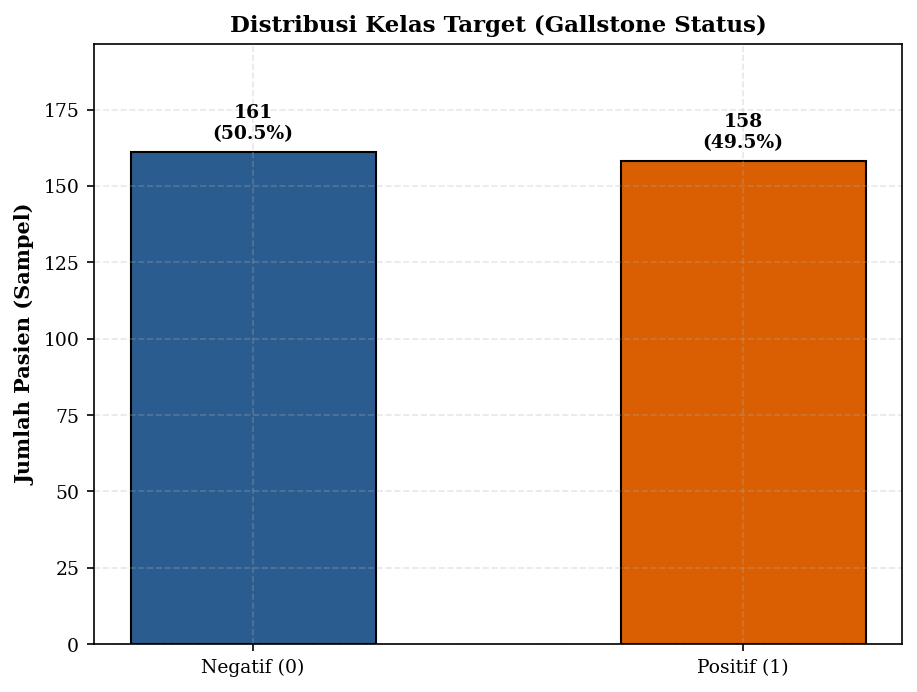

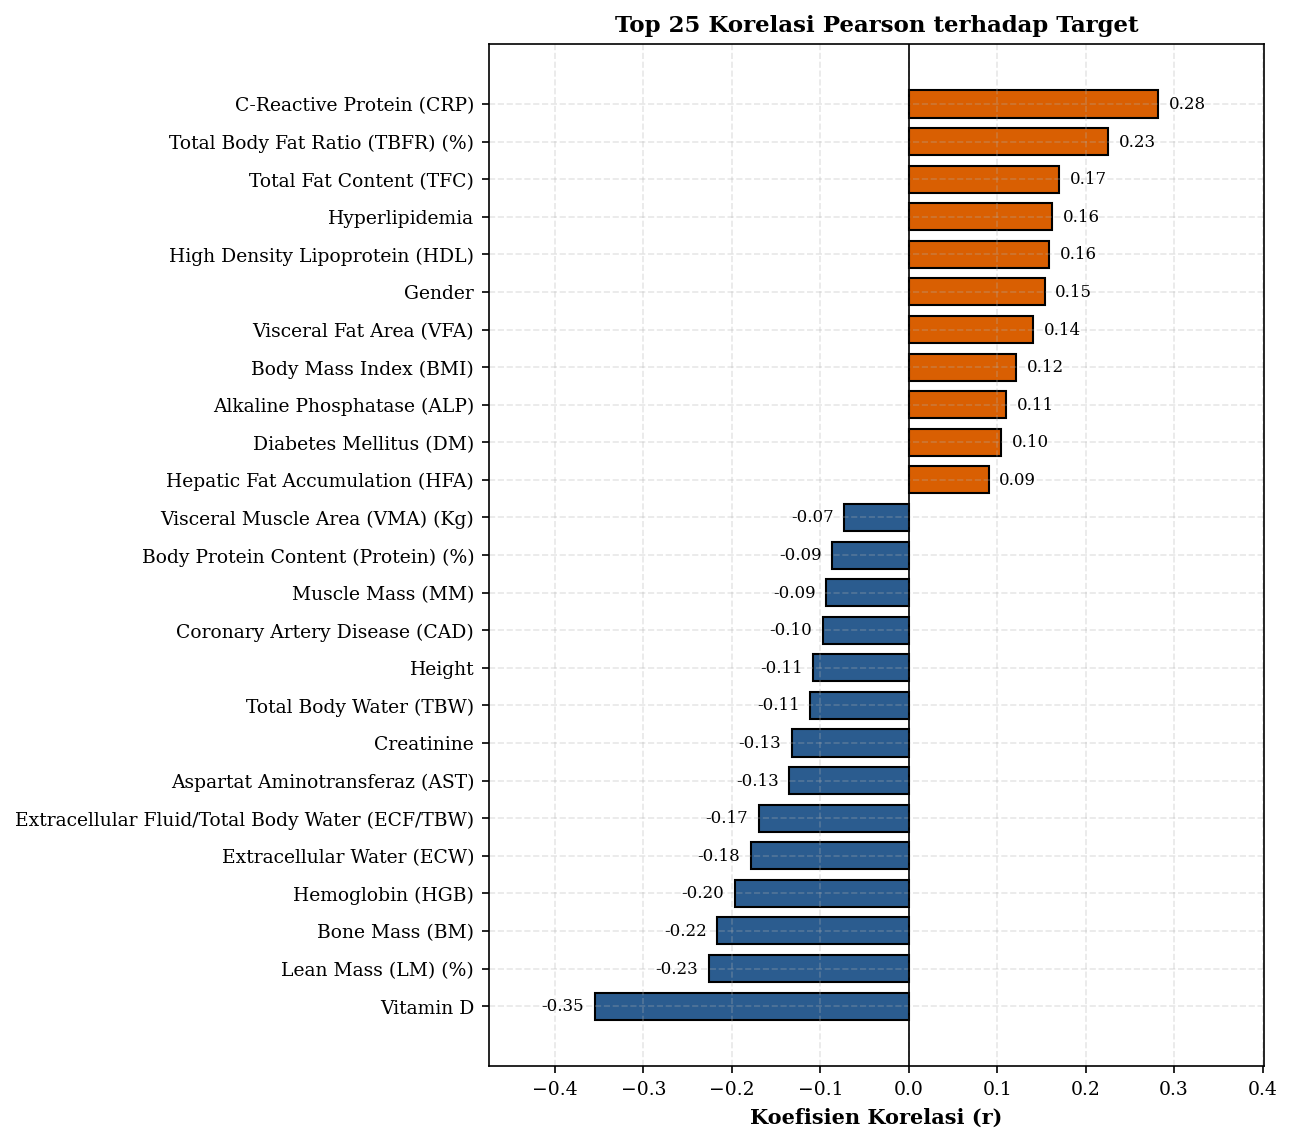

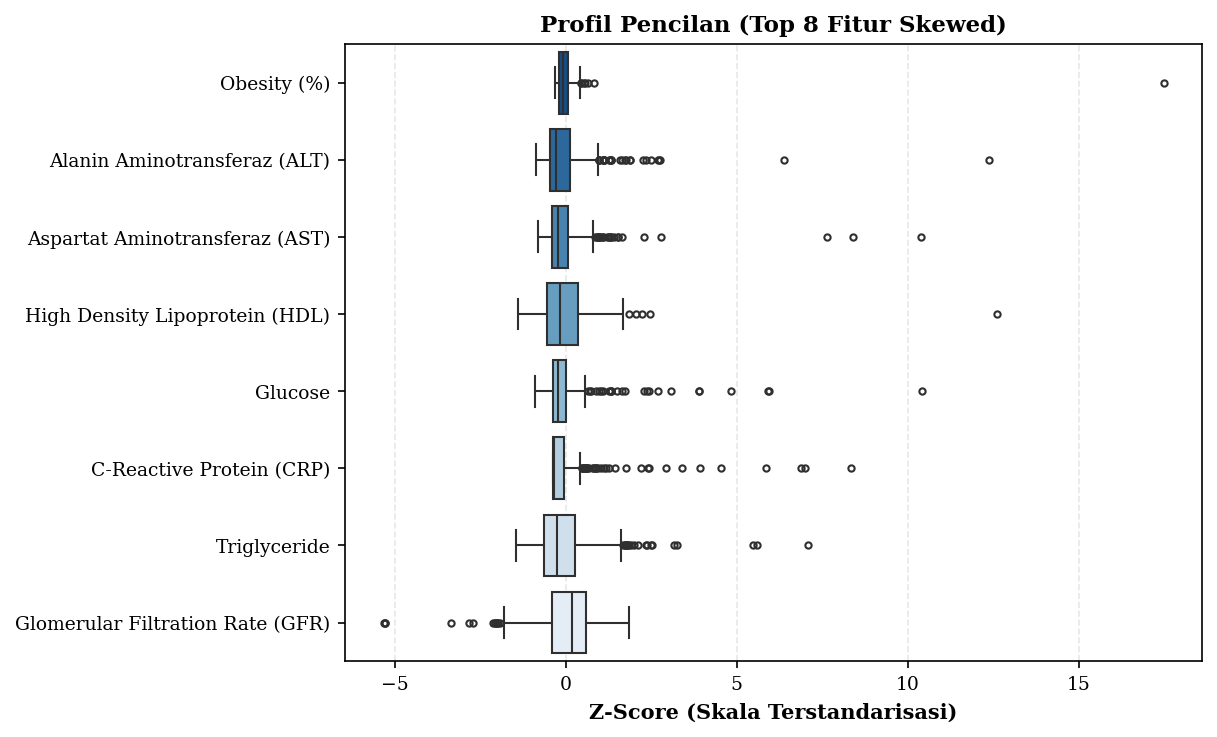

In [12]:
# ==============================================================================
# 3B. VISUALISASI DISTRIBUSI TARGET, TOP-25 KORELASI PEARSON & OUTLIER AWAL (SATU PER SATU | IEEE)
# ==============================================================================

# 1. Gambar Terpisah (a): Distribusi Kelas Target
fig, ax0 = plt.subplots(figsize=(6.0, 4.5), constrained_layout=True)
counts = y_data.value_counts().sort_index()
labels_target = ['Negatif (0)', 'Positif (1)']
bars = ax0.bar(labels_target, counts.values, color=['#2b5c8f', '#d95f02'], width=0.5, edgecolor='black')
for bar in bars:
    h = bar.get_height()
    pct = (h / len(y_data)) * 100
    ax0.text(bar.get_x() + bar.get_width()/2., h + (max(counts.values)*0.02),
             f"{int(h)}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')
ax0.set_ylim(0, max(counts.values) * 1.22)
ax0.set_title("Distribusi Kelas Target (Gallstone Status)")
ax0.set_ylabel("Jumlah Pasien (Sampel)")
plt.savefig("Fig1a_Distribusi_Target_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. Gambar Terpisah (b): Top 25 Korelasi Fitur terhadap Target
fig, ax1 = plt.subplots(figsize=(8.5, 7.5), constrained_layout=True)
corr_series = X_data.apply(lambda col: col.corr(y_data)).dropna()
top_corr = corr_series.reindex(corr_series.abs().sort_values(ascending=False).index).head(25).sort_values()
colors_corr = ['#d95f02' if val > 0 else '#2b5c8f' for val in top_corr.values]
bars_corr = ax1.barh(top_corr.index, top_corr.values, color=colors_corr, edgecolor='black', height=0.72)
ax1.axvline(0, color='black', linewidth=0.8)
for bar in bars_corr:
    w = bar.get_width()
    offset = 0.012 if w >= 0 else -0.012
    ha_align = 'left' if w >= 0 else 'right'
    ax1.text(w + offset, bar.get_y() + bar.get_height()/2., f"{w:.2f}",
             ha=ha_align, va='center', fontsize=8)
min_c, max_c = top_corr.values.min(), top_corr.values.max()
ax1.set_xlim(min(min_c - 0.12, -0.1), max(max_c + 0.12, 0.1))
ax1.set_title("Top 25 Korelasi Pearson terhadap Target")
ax1.set_xlabel("Koefisien Korelasi (r)")
plt.savefig("Fig1b_Top25_Korelasi_Pearson_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# 3. Gambar Terpisah (c): Boxplot 8 Fitur Kontinu Paling Miring (Deteksi Outlier Mentah)
fig, ax2 = plt.subplots(figsize=(8.0, 4.8), constrained_layout=True)
continuous_cols = [c for c in X_data.columns if X_data[c].nunique() > 10]
top_skew_cols = X_data[continuous_cols].skew().abs().sort_values(ascending=False).head(8).index.tolist()
X_z_temp = (X_data[top_skew_cols] - X_data[top_skew_cols].mean()) / X_data[top_skew_cols].std()
sns.boxplot(data=X_z_temp, orient='h', ax=ax2, palette='Blues_r', fliersize=3, linewidth=1)
ax2.set_title("Profil Pencilan (Top 8 Fitur Skewed)")
ax2.set_xlabel("Z-Score (Skala Terstandarisasi)")
plt.savefig("Fig1c_Profil_Pencilan_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()


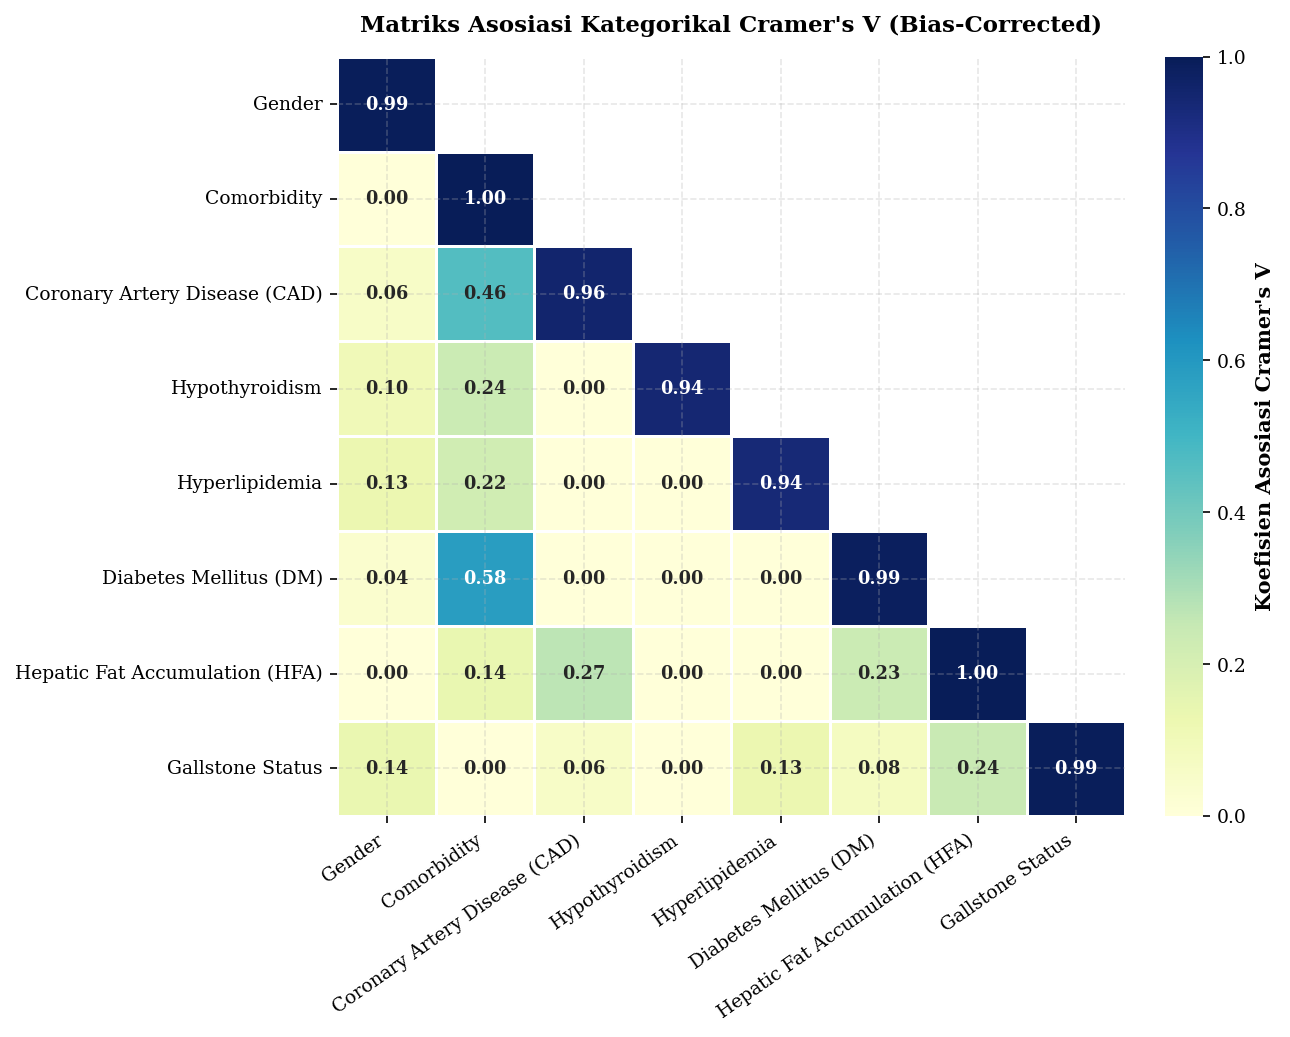

In [13]:
# ==============================================================================
# 3C. VISUALISASI MATRIKS CRAMER'S V (VARIABEL KATEGORIKAL & TARGET)
# ==============================================================================
def cramers_v_corrected(x, y):
    """Menghitung koefisien Cramer's V dengan koreksi bias Bergsma & Wicher (2013)."""
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return 0.0
    chi2 = chi2_contingency(ct)[0]
    n = ct.sum().sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2_corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    denom = min((k_corr - 1), (r_corr - 1))
    return np.sqrt(phi2_corr / denom) if denom > 0 else 0.0

# Identifikasi fitur kategorikal/diskrit asli (nunique <= 6)
cat_cols = [c for c in X_data.columns if X_data[c].nunique() <= 6]
cat_df = pd.DataFrame(index=X_data.index)

if len(cat_cols) >= 3:
    for c in cat_cols[:10]:
        cat_df[c] = X_data[c].astype(str)
else:
    for c in X_data.columns[:8]:
        cat_df[c] = pd.qcut(X_data[c], q=3, labels=['Rendah', 'Sedang', 'Tinggi'], duplicates='drop').astype(str)

cat_df['Gallstone Status'] = y_data.map({0: 'Negatif', 1: 'Positif'})

cols_cv = cat_df.columns.tolist()
n_cv = len(cols_cv)
cramers_mat = pd.DataFrame(np.zeros((n_cv, n_cv)), index=cols_cv, columns=cols_cv)

for i in range(n_cv):
    for j in range(n_cv):
        cramers_mat.iloc[i, j] = cramers_v_corrected(cat_df.iloc[:, i], cat_df.iloc[:, j])

fig, ax = plt.subplots(figsize=(8.5, 6.8), constrained_layout=True)
mask_upper = np.triu(np.ones_like(cramers_mat, dtype=bool), k=1)
sns.heatmap(
    cramers_mat, mask=mask_upper, annot=True, fmt='.2f', cmap='YlGnBu',
    vmin=0.0, vmax=1.0, cbar_kws={'label': "Koefisien Asosiasi Cramer's V"},
    linewidths=0.5, annot_kws={'size': 8.5, 'weight': 'bold'}, ax=ax
)
ax.set_title("Matriks Asosiasi Kategorikal Cramer's V (Bias-Corrected)", pad=12)
plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)
plt.savefig("Fig2_Cramers_V_Heatmap_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

=== ANALISIS MULTIKOLINEARITAS AWAL (EDA VIF) PADA 38 FITUR ===
Jumlah fitur dengan VIF > 10 : 14/38 fitur


,Fitur,VIF_Awal_EDA
0,Weight,224.759488
1,Lean Mass (LM) (%),114.737400
2,Extracellular Water (ECW),112.502586
3,Total Body Fat Ratio (TBFR) (%),96.879911
4,Body Mass Index (BMI),76.735420
5,Height,36.145810
6,Visceral Fat Area (VFA),34.634050
7,Total Body Water (TBW),34.365416
8,Visceral Fat Rating (VFR),24.631541
9,Total Fat Content (TFC),23.417120


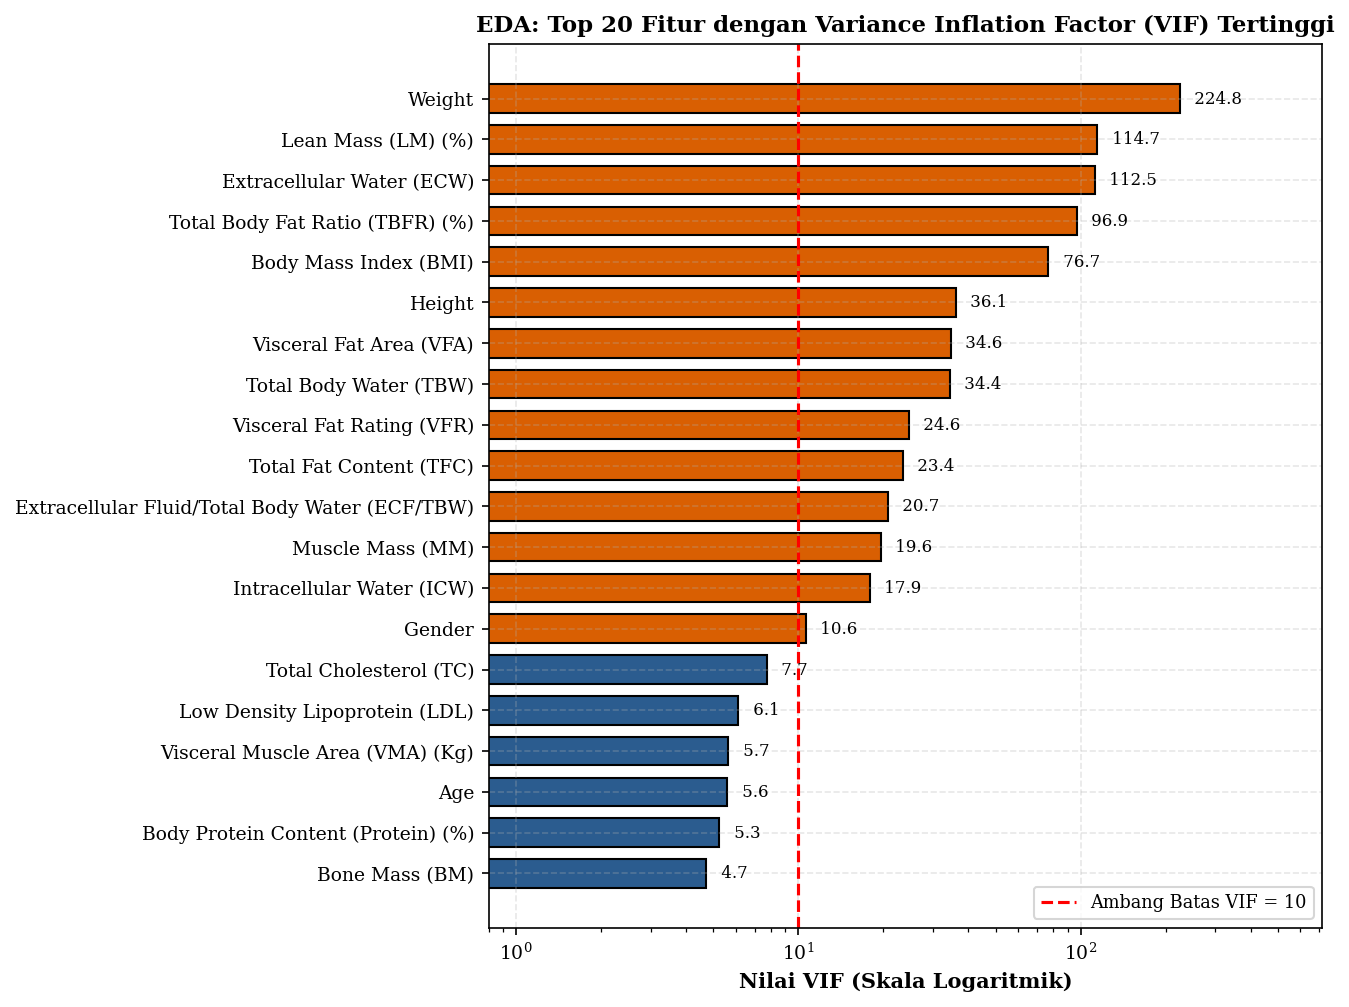

In [14]:
# ==============================================================================
# 3D. ANALISIS MULTIKOLINEARITAS AWAL (VARIANCE INFLATION FACTOR / VIF)
# ==============================================================================
import statsmodels.api as sm

# Standarisasi sementara pada data mentah + konstanta untuk kestabilan numerik OLS VIF
X_eda_std = (X_data - X_data.mean()) / X_data.std().replace(0, 1)
X_eda_const = sm.add_constant(X_eda_std, has_constant='add')

eda_vif_records = []
for idx, col in enumerate(X_eda_const.columns):
    if col == 'const':
        continue
    vif_val = variance_inflation_factor(X_eda_const.values, idx)
    eda_vif_records.append({'Fitur': col, 'VIF_Awal_EDA': vif_val})

eda_vif_df = pd.DataFrame(eda_vif_records).sort_values(by='VIF_Awal_EDA', ascending=False).reset_index(drop=True)
n_high_vif = (eda_vif_df['VIF_Awal_EDA'] > 10.0).sum()
print(f"=== ANALISIS MULTIKOLINEARITAS AWAL (EDA VIF) PADA {X_data.shape[1]} FITUR ===")
print(f"Jumlah fitur dengan VIF > 10 : {n_high_vif}/{len(eda_vif_df)} fitur")
display(eda_vif_df.head(15))

# Visualisasi Top-20 Fitur dengan VIF Tertinggi pada EDA (IEEE Style)
fig, ax = plt.subplots(figsize=(8.8, 6.6), constrained_layout=True)
top20_eda_vif = eda_vif_df.head(20).iloc[::-1]
colors_eda_vif = ['#d95f02' if v > 10.0 else '#2b5c8f' for v in top20_eda_vif['VIF_Awal_EDA']]
bars_vif = ax.barh(top20_eda_vif['Fitur'], top20_eda_vif['VIF_Awal_EDA'], color=colors_eda_vif, edgecolor='black', height=0.70)
ax.axvline(10.0, color='red', linestyle='--', linewidth=1.5, label='Ambang Batas VIF = 10')

if top20_eda_vif['VIF_Awal_EDA'].max() > 10.0:
    ax.set_xscale('log')
    ax.set_xlabel("Nilai VIF (Skala Logaritmik)")
    ax.set_xlim(0.8, top20_eda_vif['VIF_Awal_EDA'].max() * 3.2)
else:
    ax.set_xlabel("Nilai VIF")
    ax.set_xlim(0, max(top20_eda_vif['VIF_Awal_EDA'].max() * 1.18, 12))

for bar in bars_vif:
    w = bar.get_width()
    pos_x = w * 1.08 if top20_eda_vif['VIF_Awal_EDA'].max() > 10.0 else w + 0.3
    ax.text(pos_x, bar.get_y() + bar.get_height()/2., f" {w:.1f}", va='center', ha='left', fontsize=8)

ax.set_title("EDA: Top 20 Fitur dengan Variance Inflation Factor (VIF) Tertinggi")
ax.legend(loc='lower right')
plt.savefig("Fig2b_EDA_VIF_Awal_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()


## Tahap 4: Pembagian Data Stratified (80:20) & Preprocessing Klinis
Untuk mencegah *data leakage*, dataset dibagi terlebih dahulu dengan skema **Stratified 80% Train Set (255 sampel) dan 20% Blind Test Set (64 sampel)**. Seluruh parameter `ClinicalPreprocessor` (seleksi kolom miring $\text{skewness} > 0.75$ untuk transformasi $\log(1+x)$, batas *winsorizing* `IQRCapper` $k=1.5$, dan `StandardScaler`) di-*fit* **murni pada Train Set (80%)**.

### 4A-2: Analisis Komparasi Distribusi Sebelum vs Sesudah Pembagian Data (Full Dataset vs Train 80% vs Test 20%)
Dalam laporan berstandar **IEEE**, pembagian data (*data splitting*) wajib divalidasi secara statistik untuk membuktikan tidak terjadinya *covariate shift* atau ketimpangan representasi klinis antara **Data Utuh ( Sebelum Split, $N=319$ )**, **Train Set ( $80\%, N=255$ )**, dan **Blind Test Set ( $20\%, N=64$ )**:
1. **Konsistensi Proporsi Kelas Target:** Membandingkan persentase kelas *Negatif (0)* dan *Positif (1)* sebelum dan sesudah *Stratified Split*.
2. **Tabel Komparasi Statistik & Uji Hipotesis Dua Sampel (KS-Test & Mann-Whitney U):** Menguji apakah distribusi fitur pada *Train Set* dan *Test Set* berbeda secara signifikan ($p\text{-value} > 0.05$ membuktikan kedua subset berasal dari distribusi populasi yang identik / **Homogen**).
3. **Visualisasi Multi-Panel (IEEE 300 DPI):** Menampilkan proporsi target, perbandingan kurva kepadatan probabilitas (*Kernel Density Estimation* / KDE) 3 kohort (*Full*, *Train*, *Test*), perbandingan *standardized mean* ($\mu \pm \text{SD}$), serta distribusi nilai $p\text{-value}$ dari uji Kolmogorov-Smirnov.

=== 1. VERIFIKASI STRATIFIKASI KELAS TARGET (SEBELUM VS SESUDAH SPLIT 80:20) ===


,Kohort Data,Total Sampel (N),Negatif / Sehat (0),Positif / Gallstone (1),Proporsi Negatif (%),Proporsi Positif (%)
0,1. Sebelum Split (Full Dataset 100%),319,161,158,50.47,49.53
1,2. Sesudah Split: Train Set (80%),255,129,126,50.59,49.41
2,3. Sesudah Split: Blind Test Set (20%),64,32,32,50.00,50.00



=== 2. RINGKASAN UJI HOMOGENITAS FITUR ANTARA DATA SEBELUM & SESUDAH SPLIT ===
Total Fitur Diuji : 38 fitur | Fitur Homogen (KS p-value > 0.05): 38/38 fitur (100.0%)


,Fitur Klinis,Full Mean ± SD,Train (80%) Mean ± SD,Test (20%) Mean ± SD,Full Median (IQR),Train Median (IQR),Test Median (IQR),KS Stat,KS p-value,Mann-Whitney p-val,Status Distribusi
0,Age,48.07 ± 12.11,48.17 ± 12.38,47.66 ± 11.07,49.00 (17.50),50.00 (18.00),48.00 (13.25),0.0792,0.8758,0.8089,Identik / Homogen (p > 0.05)
1,Gender,0.49 ± 0.50,0.50 ± 0.50,0.47 ± 0.50,0.00 (1.00),0.00 (1.00),0.00 (1.00),0.0293,1.0000,0.6763,Identik / Homogen (p > 0.05)
2,Comorbidity,0.34 ± 0.52,0.34 ± 0.51,0.33 ± 0.56,0.00 (1.00),0.00 (1.00),0.00 (1.00),0.0286,1.0000,0.6942,Identik / Homogen (p > 0.05)
3,Coronary Artery Disease (CAD),0.04 ± 0.19,0.03 ± 0.17,0.06 ± 0.24,0.00 (0.00),0.00 (0.00),0.00 (0.00),0.0311,1.0000,0.2436,Identik / Homogen (p > 0.05)
4,Hypothyroidism,0.03 ± 0.17,0.04 ± 0.18,0.00 ± 0.00,0.00 (0.00),0.00 (0.00),0.00 (0.00),0.0353,1.0000,0.1286,Identik / Homogen (p > 0.05)
5,Hyperlipidemia,0.03 ± 0.16,0.02 ± 0.15,0.03 ± 0.18,0.00 (0.00),0.00 (0.00),0.00 (0.00),0.0077,1.0000,0.7265,Identik / Homogen (p > 0.05)
6,Diabetes Mellitus (DM),0.13 ± 0.34,0.14 ± 0.34,0.12 ± 0.33,0.00 (0.00),0.00 (0.00),0.00 (0.00),0.0123,1.0000,0.7987,Identik / Homogen (p > 0.05)
7,Height,167.16 ± 10.05,167.36 ± 10.21,166.36 ± 9.42,168.00 (15.50),168.00 (16.00),166.50 (15.00),0.1112,0.5104,0.5172,Identik / Homogen (p > 0.05)
8,Weight,80.56 ± 15.71,80.44 ± 15.35,81.06 ± 17.18,78.80 (21.65),79.00 (21.35),78.00 (23.17),0.0778,0.8856,0.7966,Identik / Homogen (p > 0.05)
9,Body Mass Index (BMI),28.88 ± 5.31,28.82 ± 5.45,29.11 ± 4.78,28.30 (6.60),28.20 (6.60),28.95 (6.77),0.1152,0.4658,0.3785,Identik / Homogen (p > 0.05)


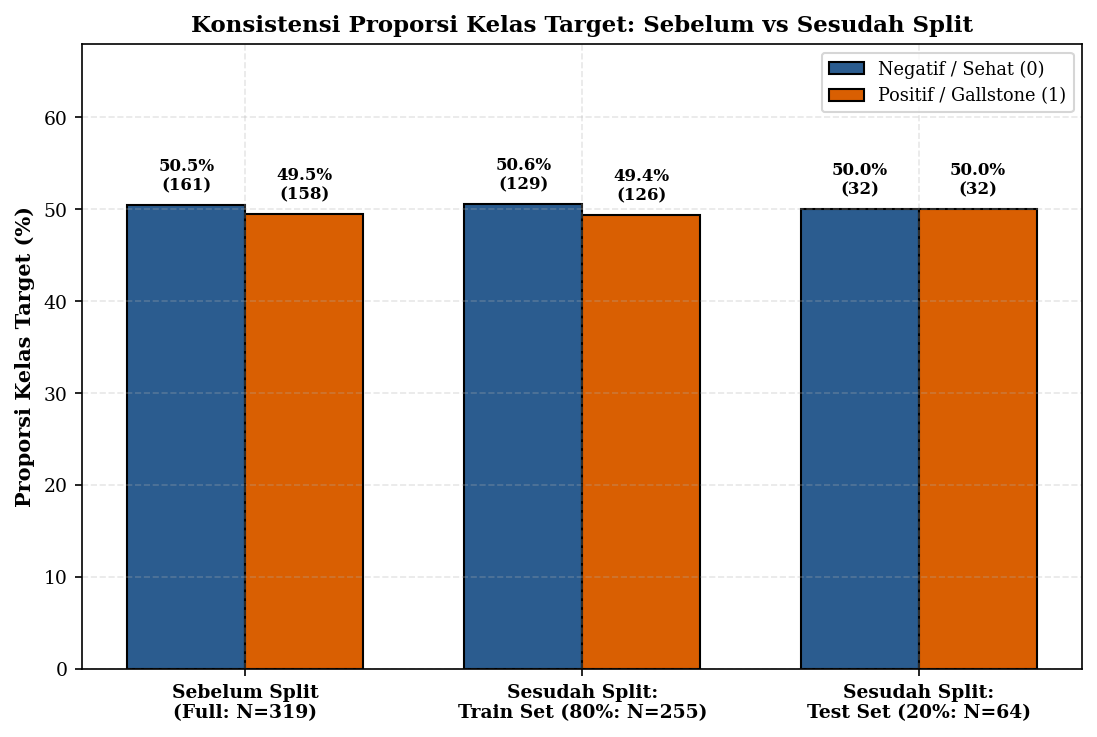

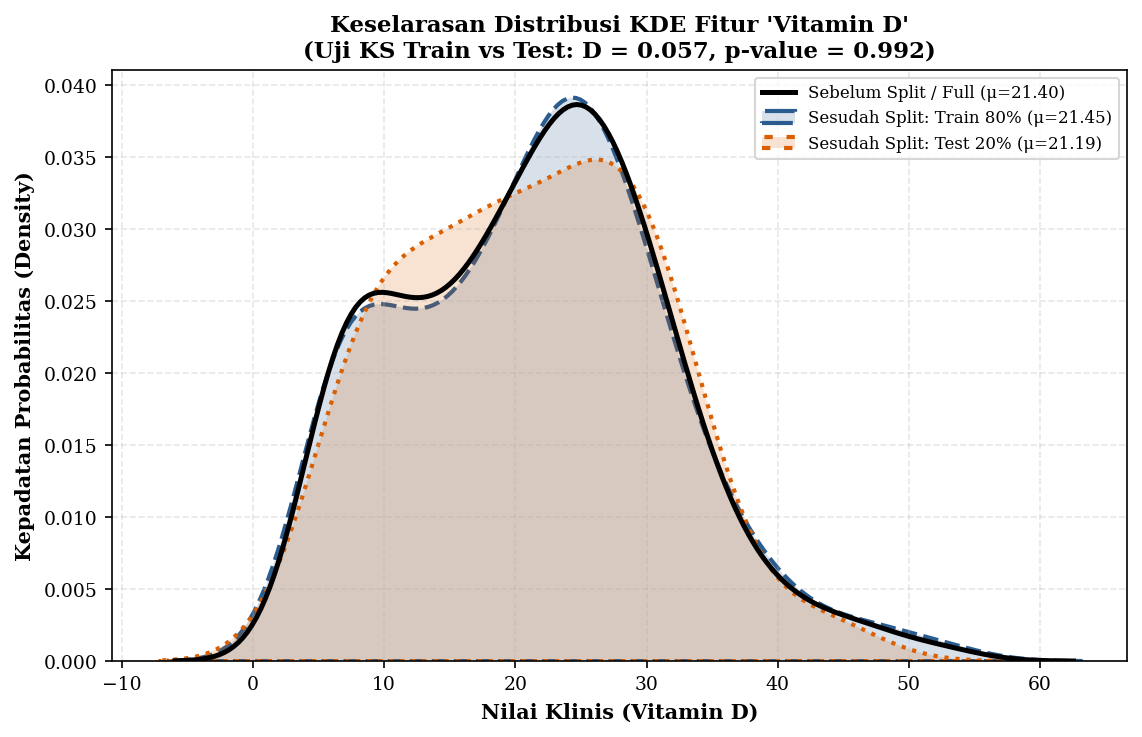

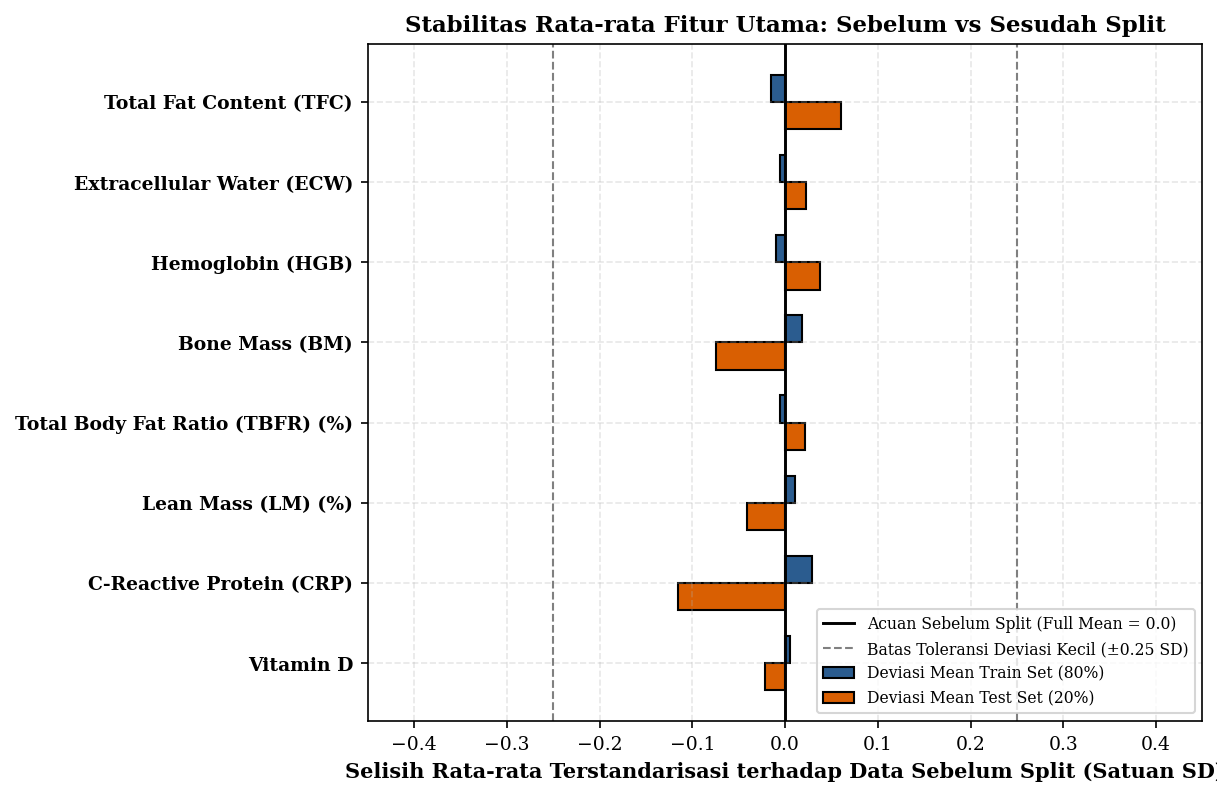

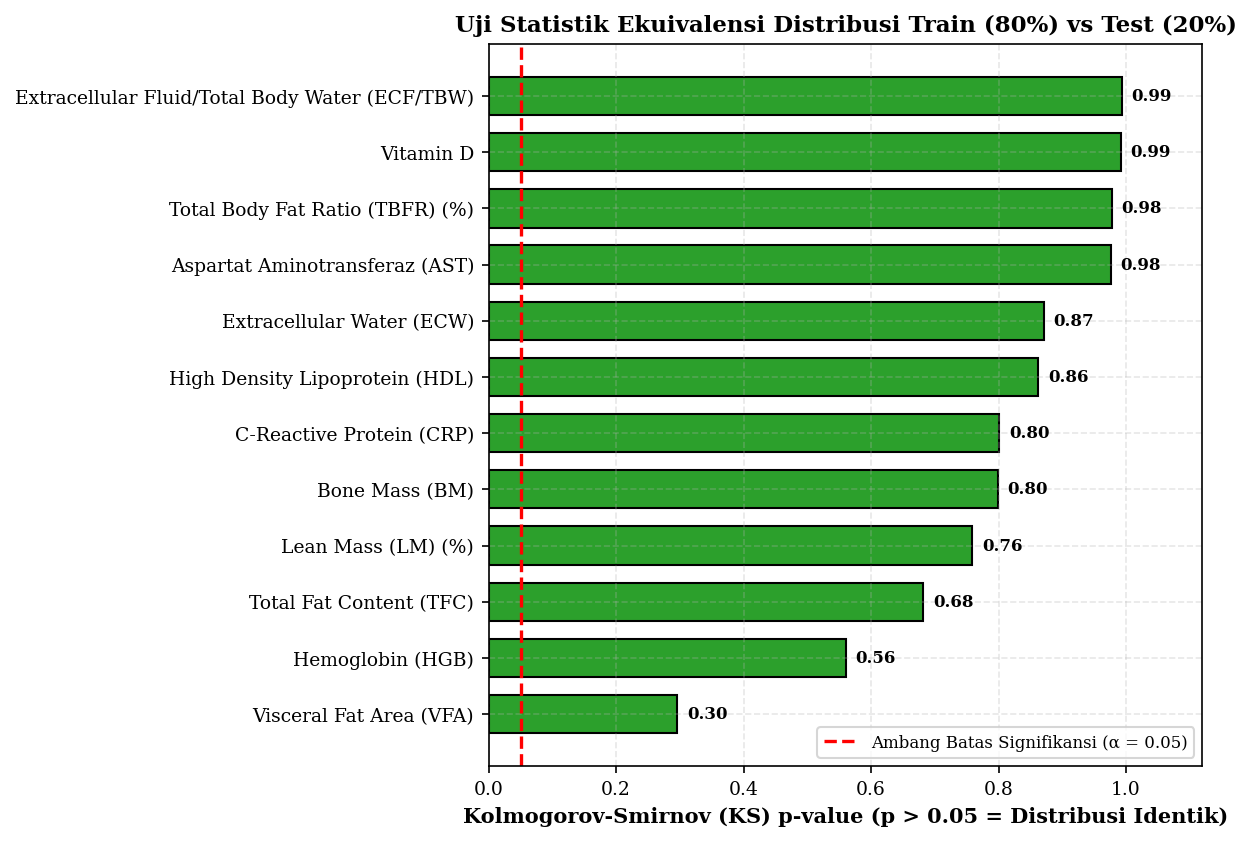

In [15]:
# ==============================================================================
# 4A-2. ANALISIS STATISTIK & VISUALISASI SEBELUM VS SESUDAH SPLIT (80:20)
# ==========================================================================
# Definisikan split terlebih dahulu untuk menghindari NameError jika sel di bawah belum dijalankan
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.20, stratify=y_data, random_state=RANDOM_STATE
)

# 1. Tabel Perbandingan Distribusi Kelas Target (Sebelum vs Sesudah Split)
target_comp_df = pd.DataFrame({
    'Kohort Data': ['1. Sebelum Split (Full Dataset 100%)', '2. Sesudah Split: Train Set (80%)', '3. Sesudah Split: Blind Test Set (20%)'],
    'Total Sampel (N)': [len(y_data), len(y_train), len(y_test)],
    'Negatif / Sehat (0)': [(y_data == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    'Positif / Gallstone (1)': [(y_data == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
    'Proporsi Negatif (%)': [round((y_data == 0).mean()*100, 2), round((y_train == 0).mean()*100, 2), round((y_test == 0).mean()*100, 2)],
    'Proporsi Positif (%)': [round((y_data == 1).mean()*100, 2), round((y_train == 1).mean()*100, 2), round((y_test == 1).mean()*100, 2)]
})
print("=== 1. VERIFIKASI STRATIFIKASI KELAS TARGET (SEBELUM VS SESUDAH SPLIT 80:20) ===")
display(target_comp_df)

# 2. Analisis Ekuivalensi Fitur & Uji Kolmogorov-Smirnov (KS-Test) / Mann-Whitney U
split_eval_records = []
for col in X_data.columns:
    s_full = X_data[col].dropna()
    s_tr = X_train_raw[col].dropna()
    s_te = X_test_raw[col].dropna()

    ks_stat, ks_pval = ks_2samp(s_tr, s_te)
    _, mw_pval = mannwhitneyu(s_tr, s_te, alternative='two-sided')

    split_eval_records.append({
        'Fitur Klinis': col,
        'Full Mean ± SD': f"{s_full.mean():.2f} ± {s_full.std():.2f}",
        'Train (80%) Mean ± SD': f"{s_tr.mean():.2f} ± {s_tr.std():.2f}",
        'Test (20%) Mean ± SD': f"{s_te.mean():.2f} ± {s_te.std():.2f}",
        'Full Median (IQR)': f"{s_full.median():.2f} ({s_full.quantile(0.75)-s_full.quantile(0.25):.2f})",
        'Train Median (IQR)': f"{s_tr.median():.2f} ({s_tr.quantile(0.75)-s_tr.quantile(0.25):.2f})",
        'Test Median (IQR)': f"{s_te.median():.2f} ({s_te.quantile(0.75)-s_te.quantile(0.25):.2f})",
        'KS Stat': round(ks_stat, 4),
        'KS p-value': round(ks_pval, 4),
        'Mann-Whitney p-val': round(mw_pval, 4),
        'Status Distribusi': 'Identik / Homogen (p > 0.05)' if ks_pval > 0.05 else 'Deviasi Signifikan'
    })

split_comp_df = pd.DataFrame(split_eval_records)
split_comp_df.to_csv("Analisis_Komparasi_Sebelum_Sesudah_Split_80_20.csv", index=False)

homogen_count = (split_comp_df['KS p-value'] > 0.05).sum()
print(f"\n=== 2. RINGKASAN UJI HOMOGENITAS FITUR ANTARA DATA SEBELUM & SESUDAH SPLIT ===")
print(f"Total Fitur Diuji : {len(split_comp_df)} fitur | Fitur Homogen (KS p-value > 0.05): {homogen_count}/{len(split_comp_df)} fitur ({homogen_count/len(split_comp_df)*100:.1f}%)")
display(split_comp_df.head(15))

# 3. Visualisasi Terpisah (Satu per Satu | IEEE 300 DPI)
kohort_labels = ['Sebelum Split\n(Full: N=319)', 'Sesudah Split:\nTrain Set (80%: N=255)', 'Sesudah Split:\nTest Set (20%: N=64)']
neg_pcts = target_comp_df['Proporsi Negatif (%)'].values
pos_pcts = target_comp_df['Proporsi Positif (%)'].values
neg_cnts = target_comp_df['Negatif / Sehat (0)'].values
pos_cnts = target_comp_df['Positif / Gallstone (1)'].values

# Gambar (a): Komparasi Proporsi Kelas Target (Full vs Train vs Test)
fig, ax0 = plt.subplots(figsize=(7.2, 4.8), constrained_layout=True)
x_k = np.arange(len(kohort_labels))
bw = 0.35
b_neg = ax0.bar(x_k - bw/2, neg_pcts, width=bw, label='Negatif / Sehat (0)', color='#2b5c8f', edgecolor='black')
b_pos = ax0.bar(x_k + bw/2, pos_pcts, width=bw, label='Positif / Gallstone (1)', color='#d95f02', edgecolor='black')

for idx_b, bar in enumerate(b_neg):
    h = bar.get_height()
    ax0.text(bar.get_x() + bar.get_width()/2., h + 1.2, f"{h:.1f}%\n({neg_cnts[idx_b]})", ha='center', va='bottom', fontsize=8, fontweight='bold')
for idx_b, bar in enumerate(b_pos):
    h = bar.get_height()
    ax0.text(bar.get_x() + bar.get_width()/2., h + 1.2, f"{h:.1f}%\n({pos_cnts[idx_b]})", ha='center', va='bottom', fontsize=8, fontweight='bold')

ax0.set_xticks(x_k)
ax0.set_xticklabels(kohort_labels, fontweight='bold')
ax0.set_ylim(0, 68)
ax0.set_ylabel("Proporsi Kelas Target (%)")
ax0.set_title("Konsistensi Proporsi Kelas Target: Sebelum vs Sesudah Split")
ax0.legend(loc='upper right')
plt.savefig("Fig3Aa_Proporsi_Target_Split_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Gambar (b): Overlay Kurva Kepadatan (KDE) Fitur Utama (Full vs Train 80% vs Test 20%)
fig, ax1 = plt.subplots(figsize=(7.5, 4.8), constrained_layout=True)
cont_features = [c for c in X_data.columns if X_data[c].nunique() > 12]
top_corr_cont = X_data[cont_features].apply(lambda c: abs(c.corr(y_data))).sort_values(ascending=False).index.tolist()
rep_feat = top_corr_cont[0] if len(top_corr_cont) > 0 else X_data.columns[0]

sns.kdeplot(X_data[rep_feat], ax=ax1, color='black', lw=2.4, ls='-', label=f"Sebelum Split / Full (μ={X_data[rep_feat].mean():.2f})")
sns.kdeplot(X_train_raw[rep_feat], ax=ax1, color='#2b5c8f', lw=2.0, ls='--', fill=True, alpha=0.18, label=f"Sesudah Split: Train 80% (μ={X_train_raw[rep_feat].mean():.2f})")
sns.kdeplot(X_test_raw[rep_feat], ax=ax1, color='#d95f02', lw=2.0, ls=':', fill=True, alpha=0.18, label=f"Sesudah Split: Test 20% (μ={X_test_raw[rep_feat].mean():.2f})")

ks_rep_stat, ks_rep_p = ks_2samp(X_train_raw[rep_feat], X_test_raw[rep_feat])
ax1.set_title(f"Keselarasan Distribusi KDE Fitur '{rep_feat}'\n(Uji KS Train vs Test: D = {ks_rep_stat:.3f}, p-value = {ks_rep_p:.3f})")
ax1.set_xlabel(f"Nilai Klinis ({rep_feat})")
ax1.set_ylabel("Kepadatan Probabilitas (Density)")
ax1.legend(loc='upper right', fontsize=8)
plt.savefig("Fig3Ab_KDE_Fitur_Utama_Split_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Gambar (c): Komparasi Rata-rata Terstandarisasi (Z-Score) Top 8 Fitur Klinis (Full vs Train vs Test)
fig, ax2 = plt.subplots(figsize=(8.0, 5.2), constrained_layout=True)
top8_feats = top_corr_cont[:8] if len(top_corr_cont) >= 8 else X_data.columns[:8].tolist()
full_means = X_data[top8_feats].mean()
full_stds = X_data[top8_feats].std().replace(0, 1)

tr_z_means = ((X_train_raw[top8_feats].mean() - full_means) / full_stds).values
te_z_means = ((X_test_raw[top8_feats].mean() - full_means) / full_stds).values

y_f = np.arange(len(top8_feats))
bh = 0.34
ax2.axvline(0.0, color='black', lw=1.4, ls='-', label='Acuan Sebelum Split (Full Mean = 0.0)')
ax2.barh(y_f + bh/2, tr_z_means, height=bh, color='#2b5c8f', edgecolor='black', label='Deviasi Mean Train Set (80%)')
ax2.barh(y_f - bh/2, te_z_means, height=bh, color='#d95f02', edgecolor='black', label='Deviasi Mean Test Set (20%)')
ax2.axvline(-0.25, color='gray', lw=1.0, ls='--')
ax2.axvline(0.25, color='gray', lw=1.0, ls='--', label='Batas Toleransi Deviasi Kecil (±0.25 SD)')

ax2.set_yticks(y_f)
ax2.set_yticklabels(top8_feats, fontweight='bold')
ax2.set_xlim(-0.45, 0.45)
ax2.set_xlabel("Selisih Rata-rata Terstandarisasi terhadap Data Sebelum Split (Satuan SD)")
ax2.set_title("Stabilitas Rata-rata Fitur Utama: Sebelum vs Sesudah Split")
ax2.legend(loc='lower right', fontsize=7.5)
plt.savefig("Fig3Ac_Stabilitas_Mean_Split_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Gambar (d): P-Value Uji Kolmogorov-Smirnov (Train 80% vs Test 20%) untuk Top 12 Fitur
fig, ax3 = plt.subplots(figsize=(8.0, 5.5), constrained_layout=True)
top12_ks = split_comp_df.set_index('Fitur Klinis').loc[top_corr_cont[:12] if len(top_corr_cont) >= 12 else X_data.columns[:12]].reset_index()
top12_ks = top12_ks.sort_values(by='KS p-value', ascending=True)

ks_colors = ['#2ca02c' if p > 0.05 else '#d95f02' for p in top12_ks['KS p-value']]
bars_ks = ax3.barh(top12_ks['Fitur Klinis'], top12_ks['KS p-value'], color=ks_colors, edgecolor='black', height=0.68)
ax3.axvline(0.05, color='red', lw=1.6, ls='--', label='Ambang Batas Signifikansi (α = 0.05)')

for bar in bars_ks:
    w = bar.get_width()
    ax3.text(w + 0.015, bar.get_y() + bar.get_height()/2., f"{w:.2f}", va='center', ha='left', fontsize=8, fontweight='bold')

ax3.set_xlim(0, 1.12)
ax3.set_xlabel("Kolmogorov-Smirnov (KS) p-value (p > 0.05 = Distribusi Identik)")
ax3.set_title("Uji Statistik Ekuivalensi Distribusi Train (80%) vs Test (20%)")
ax3.legend(loc='lower right', fontsize=8)
plt.savefig("Fig3Ad_KS_PValue_Split_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()


In [16]:
# ==============================================================================
# 4A. DEFINISI TRANSFORMER & PEMBAGIAN DATA (80:20 STRATIFIED)
# ==============================================================================
class ClinicalPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self, iqr_k=1.5, skew_threshold=0.75):
        self.iqr_k = iqr_k
        self.skew_threshold = skew_threshold
        self.skewed_cols_ = []
        self.lower_bounds_ = {}
        self.upper_bounds_ = {}
        self.scaler_ = StandardScaler()
        self.feature_names_ = None

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X).copy()
        self.feature_names_ = X_df.columns.tolist()

        # 1. Identifikasi kolom kontinu yang miring (skewed) & non-negatif untuk log1p
        self.skewed_cols_ = []
        for col in self.feature_names_:
            if X_df[col].nunique() > 5 and (X_df[col] >= 0).all() and abs(X_df[col].skew()) > self.skew_threshold:
                self.skewed_cols_.append(col)
                X_df[col] = np.log1p(X_df[col])

        # 2. Hitung batas IQRCapper (k=1.5) hanya pada fitur kontinu di Train Set
        self.lower_bounds_ = {}
        self.upper_bounds_ = {}
        for col in self.feature_names_:
            if X_df[col].nunique() > 5:
                Q1 = X_df[col].quantile(0.25)
                Q3 = X_df[col].quantile(0.75)
                IQR = Q3 - Q1
                self.lower_bounds_[col] = Q1 - self.iqr_k * IQR
                self.upper_bounds_[col] = Q3 + self.iqr_k * IQR
                X_df[col] = X_df[col].clip(
                    lower=self.lower_bounds_[col],
                    upper=self.upper_bounds_[col]
                )
            else:
                self.lower_bounds_[col] = -np.inf
                self.upper_bounds_[col] = np.inf

        # 3. Fit StandardScaler
        self.scaler_.fit(X_df)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X, columns=self.feature_names_).copy()
        for col in self.skewed_cols_:
            X_df[col] = np.log1p(np.maximum(0, X_df[col]))
        for col in self.feature_names_:
            X_df[col] = X_df[col].clip(
                lower=self.lower_bounds_[col],
                upper=self.upper_bounds_[col]
            )
        X_scaled = pd.DataFrame(
            self.scaler_.transform(X_df),
            columns=self.feature_names_, index=X_df.index
        )
        return X_scaled

# Pembagian Data 80:20 Stratified (80% Train, 20% Blind Test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.20, stratify=y_data, random_state=RANDOM_STATE
)

preprocessor = ClinicalPreprocessor(iqr_k=1.5, skew_threshold=0.75)
X_train_clean = preprocessor.fit_transform(X_train_raw)
X_test_clean = preprocessor.transform(X_test_raw)

print(f"Skema Split 80:20 -> Train Set: {X_train_clean.shape[0]} sampel | Blind Test Set: {X_test_clean.shape[0]} sampel")
print(f"Jumlah Fitur yang Ditransformasi Log1p (Skewness > 0.75): {len(preprocessor.skewed_cols_)} fitur")


Skema Split 80:20 -> Train Set: 255 sampel | Blind Test Set: 64 sampel
Jumlah Fitur yang Ditransformasi Log1p (Skewness > 0.75): 13 fitur


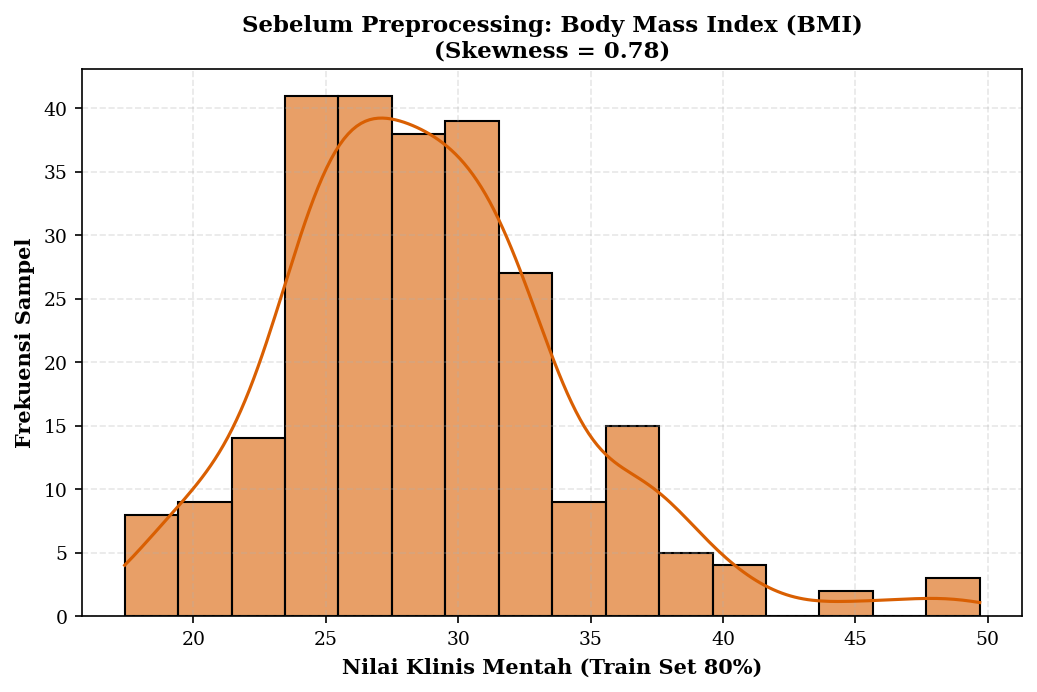

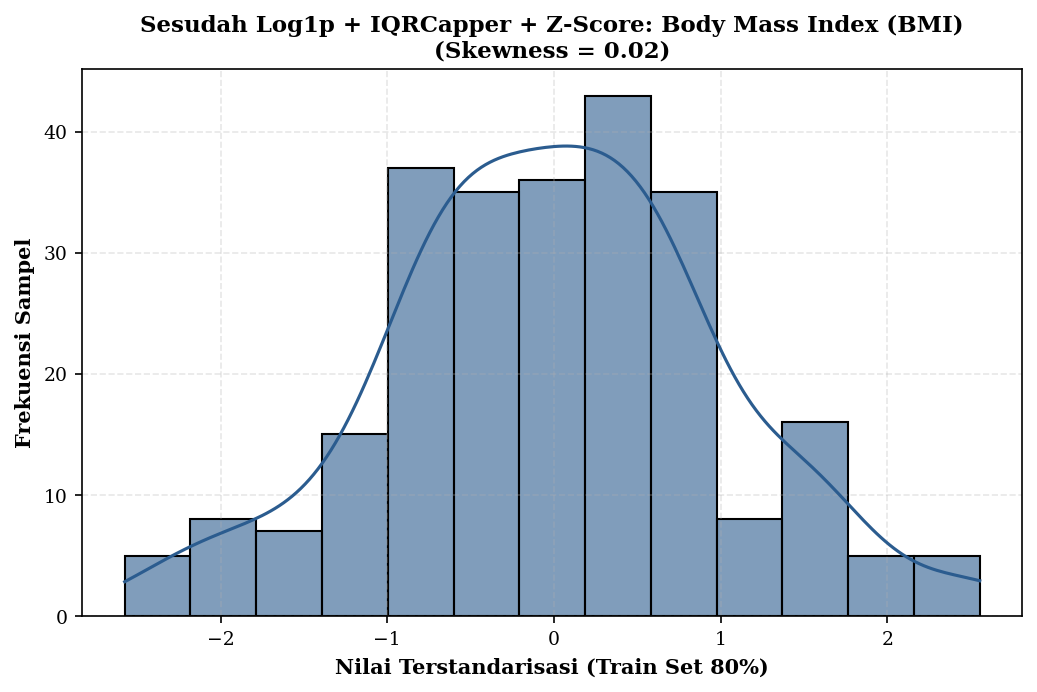

In [17]:
# ==============================================================================
# 4B. VISUALISASI KOMPARASI DISTRIBUSI SEBELUM VS SESUDAH PREPROCESSING (TERPISAH | IEEE)
# ==============================================================================
sample_skew_col = preprocessor.skewed_cols_[0] if len(preprocessor.skewed_cols_) > 0 else X_train_raw.columns[0]

# Gambar (a): Sebelum Preprocessing
fig, ax0 = plt.subplots(figsize=(6.8, 4.5), constrained_layout=True)
sns.histplot(X_train_raw[sample_skew_col], kde=True, ax=ax0, color='#d95f02', edgecolor='black', alpha=0.6)
ax0.set_title(f"Sebelum Preprocessing: {sample_skew_col}\n(Skewness = {X_train_raw[sample_skew_col].skew():.2f})")
ax0.set_xlabel("Nilai Klinis Mentah (Train Set 80%)")
ax0.set_ylabel("Frekuensi Sampel")
plt.savefig("Fig3a_Sebelum_Preprocessing_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Gambar (b): Sesudah Preprocessing
fig, ax1 = plt.subplots(figsize=(6.8, 4.5), constrained_layout=True)
sns.histplot(X_train_clean[sample_skew_col], kde=True, ax=ax1, color='#2b5c8f', edgecolor='black', alpha=0.6)
ax1.set_title(f"Sesudah Log1p + IQRCapper + Z-Score: {sample_skew_col}\n(Skewness = {X_train_clean[sample_skew_col].skew():.2f})")
ax1.set_xlabel("Nilai Terstandarisasi (Train Set 80%)")
ax1.set_ylabel("Frekuensi Sampel")
plt.savefig("Fig3b_Sesudah_Preprocessing_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()


## Tahap 5: Seleksi Fitur Hibrida pada Train Set 80% (Stepwise VIF $< 10 \rightarrow$ Top-25 SHAP)
Seleksi fitur dilakukan dalam dua tahap pada `X_train_clean`:
1. **Eliminasi Multikolinearitas (Stepwise VIF $< 10$):** Menghitung *Variance Inflation Factor* untuk seluruh fitur dan mengeliminasi fitur dengan VIF tertinggi satu per satu secara iteratif hingga seluruh fitur tersisa memiliki $\text{VIF} < 10$.
2. **Ranking Kepentingan Fitur SHAP (Top-25):** Melatih model `XGBClassifier` pada fitur bebas multikolinearitas dan mengekstraksi nilai rata-rata absolut SHAP ($\text{mean}(|\text{SHAP}|)$) untuk memilih 25 fitur terbaik.

In [18]:
# ==============================================================================
# 5A. EKSEKUSI SELEKSI FITUR STEPWISE VIF < 10 DAN RANKING SHAP (DIPERBAIKI JADI VIF < 10)
# ==============================================================================
def select_features_shap_vif(X_train, y_train, top_k_shap=25, vif_threshold=10.0):
    vif_initial = pd.DataFrame({
        'feature': X_train.columns,
        'VIF': [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
    }).sort_values(by='VIF', ascending=False).reset_index(drop=True)

    X_curr = X_train.copy()
    removed_features = []
    while X_curr.shape[1] > 2:
        vif_vals = [variance_inflation_factor(X_curr.values, i) for i in range(X_curr.shape[1])]
        max_vif = max(vif_vals)
        if max_vif > vif_threshold:
            worst_idx = int(np.argmax(vif_vals))
            worst_feat = X_curr.columns[worst_idx]
            removed_features.append((worst_feat, max_vif))
            X_curr = X_curr.drop(columns=[worst_feat])
        else:
            break

    vif_cleared_features = X_curr.columns.tolist()
    vif_post_stepwise = pd.DataFrame({
        'feature': vif_cleared_features,
        'VIF': [variance_inflation_factor(X_curr.values, i) for i in range(X_curr.shape[1])]
    }).sort_values(by='VIF', ascending=False).reset_index(drop=True)

    xgb_selector = XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1
    )
    xgb_selector.fit(X_curr, y_train)

    explainer = shap.TreeExplainer(xgb_selector)
    shap_values = explainer.shap_values(X_curr)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif len(np.shape(shap_values)) == 3:
        shap_values = shap_values[:, :, 1]

    mean_abs_shap = np.abs(shap_values).mean(axis=0)
    shap_df = pd.DataFrame({
        'feature': vif_cleared_features,
        'shap_importance': mean_abs_shap
    }).sort_values(by='shap_importance', ascending=False).reset_index(drop=True)

    k = min(top_k_shap, len(vif_cleared_features))
    final_features = shap_df['feature'].head(k).tolist()

    final_vif_df = pd.DataFrame({
        'feature': final_features,
        'VIF': [variance_inflation_factor(X_train[final_features].values, i) for i in range(len(final_features))]
    }).sort_values(by='VIF', ascending=False).reset_index(drop=True)

    return final_features, shap_df, vif_initial, vif_post_stepwise, final_vif_df, shap_values, X_curr, removed_features

# Menggunakan threshold VIF < 10.0 agar selaras dengan Skenario B dan teks deskripsi
selected_features, shap_df, vif_initial_df, vif_post_df, final_vif_df, raw_shap_vals, X_vif_cleared, removed_vif_list = select_features_shap_vif(
    X_train_clean, y_train, top_k_shap=25, vif_threshold=10.0
)

X_tr = X_train_clean[selected_features].copy()
X_te = X_test_clean[selected_features].copy()

print(f"Total Fitur Awal               : {X_train_clean.shape[1]} fitur")
print(f"Fitur Tereliminasi (VIF > 10)  : {len(removed_vif_list)} fitur -> {[f[0] for f in removed_vif_list]}")
print(f"Fitur Lolos VIF < 10           : {len(vif_post_df)} fitur")
print(f"Fitur Final Terpilih (Top SHAP): {len(selected_features)} fitur")

Total Fitur Awal               : 38 fitur
Fitur Tereliminasi (VIF > 10)  : 9 fitur -> ['Total Body Fat Ratio (TBFR) (%)', 'Body Mass Index (BMI)', 'Extracellular Water (ECW)', 'Lean Mass (LM) (%)', 'Visceral Fat Area (VFA)', 'Weight', 'Muscle Mass (MM)', 'Visceral Fat Rating (VFR)', 'Intracellular Water (ICW)']
Fitur Lolos VIF < 10           : 29 fitur
Fitur Final Terpilih (Top SHAP): 25 fitur


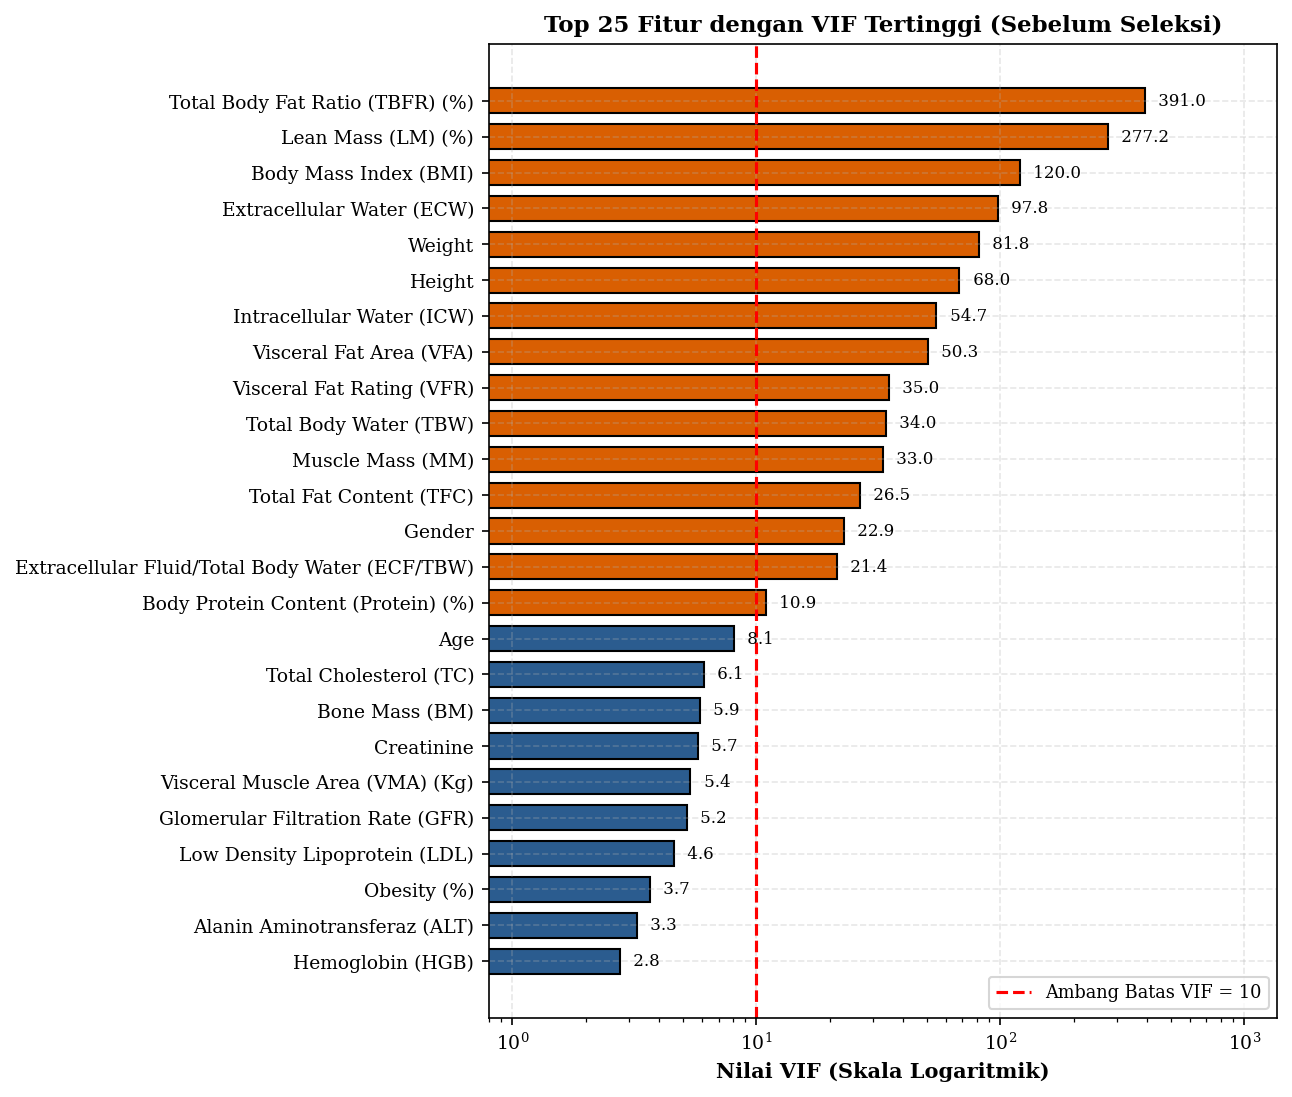

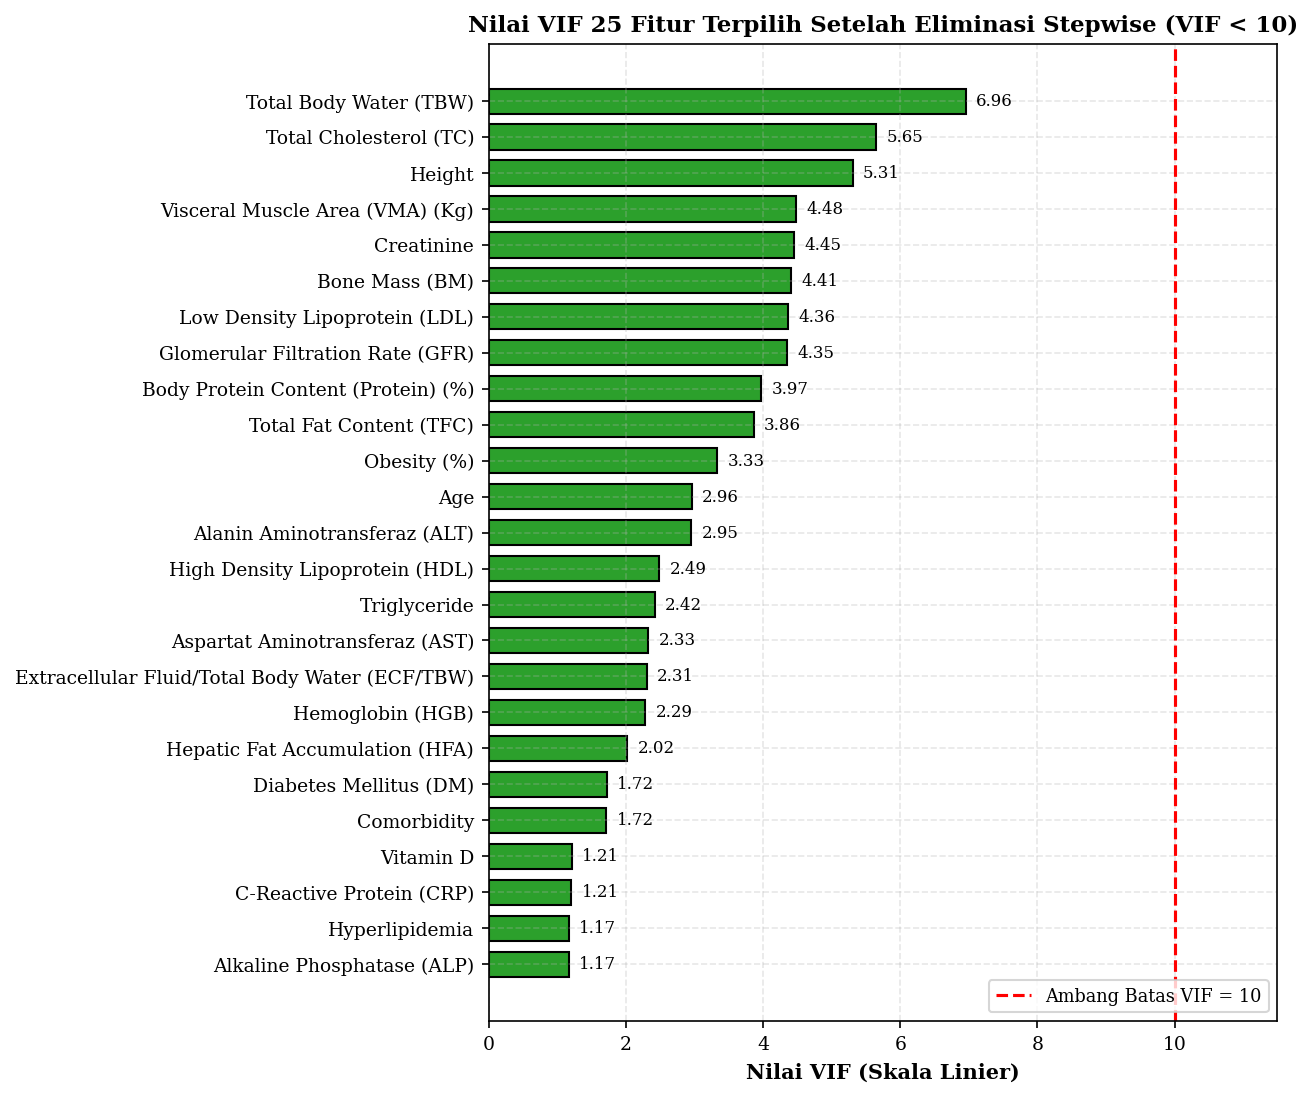

In [19]:
# ==============================================================================
# 5B. VISUALISASI VIF SEBELUM VS SESUDAH ELIMINASI STEPWISE (VIF < 10 | SATU PER SATU | IEEE)
# ==============================================================================

# 1. Gambar Terpisah (a): Top 25 VIF Awal Sebelum Eliminasi
fig, ax0 = plt.subplots(figsize=(8.5, 7.2), constrained_layout=True)
top25_init_vif = vif_initial_df.head(25).iloc[::-1]
colors_vif_init = ['#d95f02' if v > 10.0 else '#2b5c8f' for v in top25_init_vif['VIF']]
bars0 = ax0.barh(top25_init_vif['feature'], top25_init_vif['VIF'], color=colors_vif_init, edgecolor='black', height=0.70)
ax0.axvline(10.0, color='red', linestyle='--', linewidth=1.5, label='Ambang Batas VIF = 10')
if top25_init_vif['VIF'].max() > 10.0:
    ax0.set_xscale('log')
    ax0.set_xlabel("Nilai VIF (Skala Logaritmik)")
    ax0.set_xlim(0.8, top25_init_vif['VIF'].max() * 3.5)
else:
    ax0.set_xlabel("Nilai VIF")
    ax0.set_xlim(0, max(top25_init_vif['VIF'].max() * 1.18, 12))

for bar in bars0:
    w = bar.get_width()
    pos_x = w * 1.08 if top25_init_vif['VIF'].max() > 10.0 else w + (top25_init_vif['VIF'].max() * 0.02)
    ax0.text(pos_x, bar.get_y() + bar.get_height()/2., f" {w:.1f}", va='center', ha='left', fontsize=8)

ax0.set_title("Top 25 Fitur dengan VIF Tertinggi (Sebelum Seleksi)")
ax0.legend(loc='lower right')
plt.savefig("Fig4a_VIF_Sebelum_Seleksi_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. Gambar Terpisah (b): Nilai VIF pada 25 Fitur Final Terpilih (Seluruhnya < 10)
fig, ax1 = plt.subplots(figsize=(8.5, 7.2), constrained_layout=True)
final_vif_sorted = final_vif_df.head(25).iloc[::-1]
bars1 = ax1.barh(final_vif_sorted['feature'], final_vif_sorted['VIF'], color='#2ca02c', edgecolor='black', height=0.70)
ax1.axvline(10.0, color='red', linestyle='--', linewidth=1.5, label='Ambang Batas VIF = 10')
ax1.set_xlim(0, max(final_vif_sorted['VIF'].max() * 1.18, 11.5))
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 0.15, bar.get_y() + bar.get_height()/2., f"{w:.2f}", va='center', ha='left', fontsize=8)

ax1.set_title("Nilai VIF 25 Fitur Terpilih Setelah Eliminasi Stepwise (VIF < 10)")
ax1.set_xlabel("Nilai VIF (Skala Linier)")
ax1.legend(loc='lower right')
plt.savefig("Fig4b_VIF_Setelah_Seleksi_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()


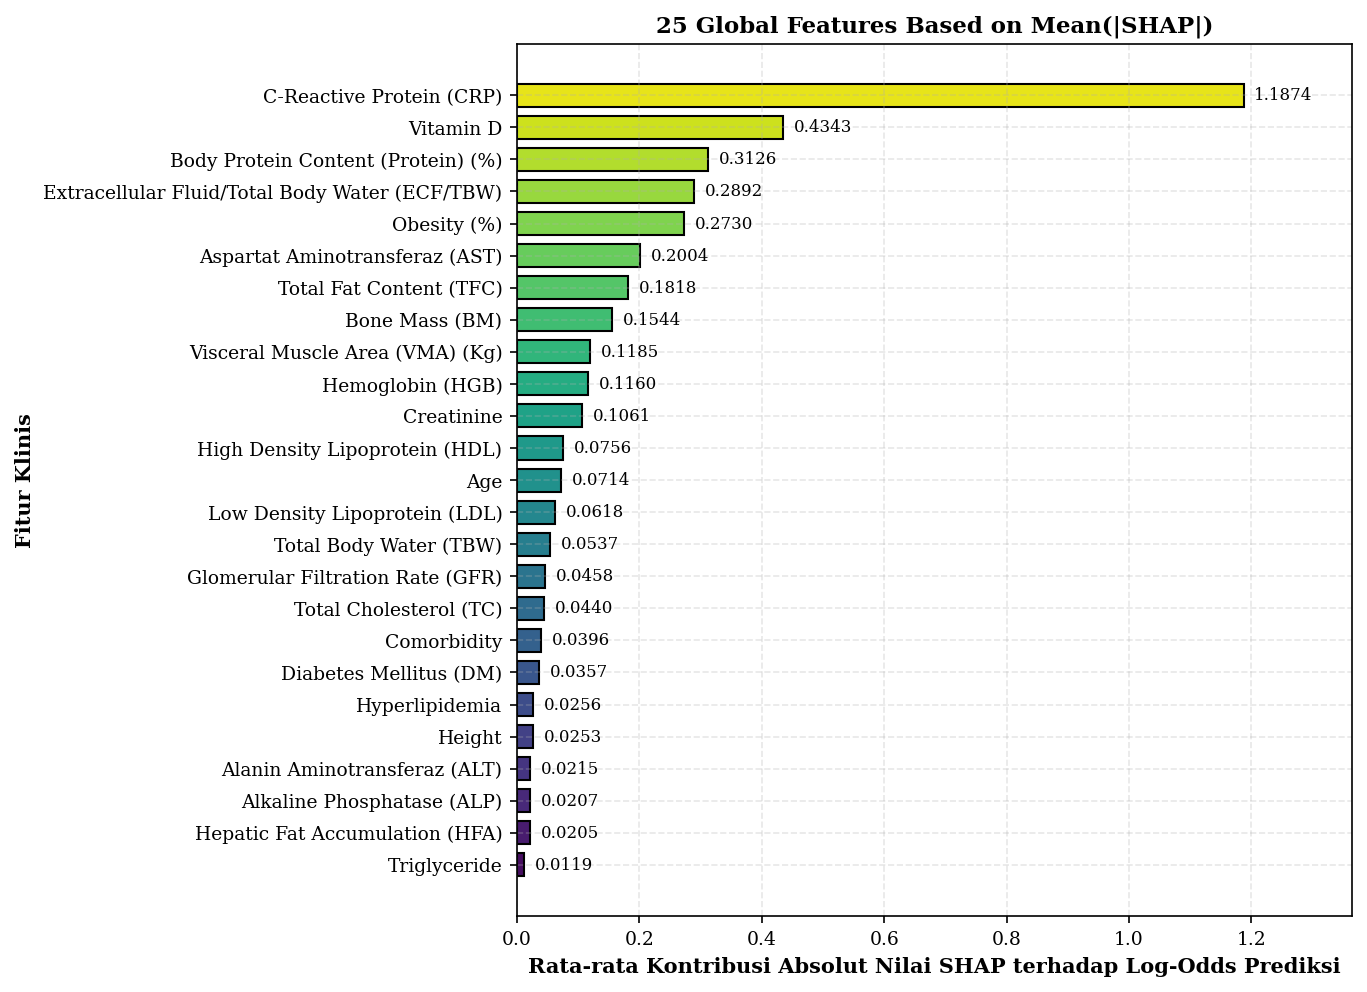

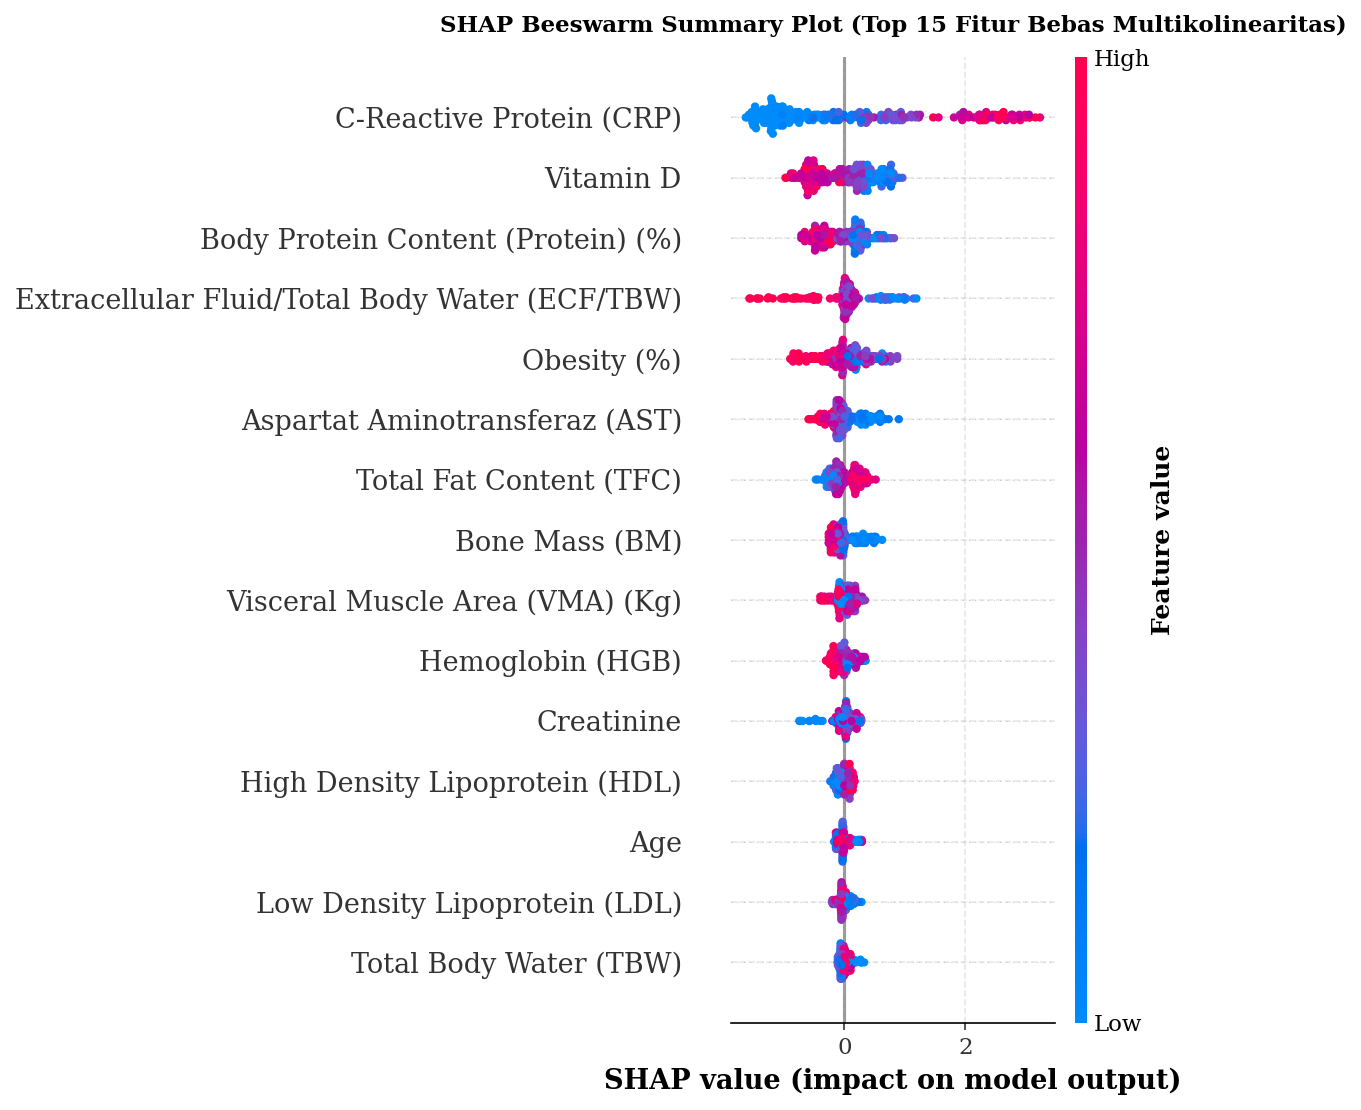

In [20]:
# ==============================================================================
# 5C. VISUALISASI RANKING FITUR SHAP (GLOBAL BAR & BEESWARM SUMMARY PLOT)
# ==============================================================================
fig, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
top_shap_plot = shap_df.head(len(selected_features)).iloc[::-1]
palette_shap = sns.color_palette("viridis", len(top_shap_plot))
bars_shap = ax.barh(top_shap_plot['feature'], top_shap_plot['shap_importance'], color=palette_shap, edgecolor='black', height=0.72)

max_s = top_shap_plot['shap_importance'].max()
for bar in bars_shap:
    w = bar.get_width()
    ax.text(w + (max_s * 0.015), bar.get_y() + bar.get_height()/2., f"{w:.4f}", va='center', ha='left', fontsize=8)

ax.set_xlim(0, max_s * 1.15)
ax.set_title(f"25 Global Features Based on Mean(|SHAP|)")
ax.set_xlabel("Rata-rata Kontribusi Absolut Nilai SHAP terhadap Log-Odds Prediksi")
ax.set_ylabel("Fitur Klinis")
plt.savefig("Fig5_SHAP_Feature_Ranking_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Visualisasi SHAP Summary Plot (Beeswarm)
plt.figure(figsize=(9, 6.2), dpi=150)
shap.summary_plot(raw_shap_vals, X_vif_cleared, max_display=15, show=False)
plt.title("SHAP Beeswarm Summary Plot (Top 15 Fitur Bebas Multikolinearitas)", fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("Fig6_SHAP_Beeswarm_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

## Tahap 6: Nested Stratified CV (Anti-Leakage), Fine-Tuning 9 Base Learners & Konstruksi 8 Model Ensemble (Skema 80:20)
Untuk mencegah *data leakage* saat seleksi fitur (`Stepwise VIF < 10 -> Top-25 SHAP`) dan optimasi *hyperparameter*, diterapkan **Nested Stratified Cross-Validation** pada **Train Set (80%)**:
- **Outer Loop (`StratifiedKFold`, 5-fold):** Memisahkan *outer-train* dan *outer-val* dari `X_train_raw`. Seluruh tahapan (`ClinicalPreprocessor`, seleksi fitur VIF+SHAP, *inner tuning* `RandomizedSearchCV`, dan pelatihan 8 ensemble) di-*fit* murni pada *outer-train* dan dievaluasi pada *outer-val*.
- **Final Model (80% Train Set):** Setelah skor Nested CV tanpa kebocoran diperoleh, 9 *base learners* dan **8 Arsitektur Ensemble** dilatih pada keseluruhan Train Set (80%) untuk dievaluasi pada **Blind Test Set (20%)**:
  - **3 Hard Voting:** `Hard Voting 1 (Top 3 Agresif)`, `Hard Voting 2 (The Strong 5)`, `Hard Voting 3 (All-In 9 Model)`.
  - **2 Soft Voting Standar (Unweighted):** `Soft Voting 1 (Trio Terkalibrasi)` dan `Soft Voting 2 (All-In 9 Model Standar)`.
  - **3 Stacking Classifier:** `Stacking 1 (Lintas Algoritma)`, `Stacking 2 (Dominasi Pohon)`, `Stacking 3 (All-In 9 Model)`.

In [21]:
# ==============================================================================
# 6A. FINE-TUNING 9 BASE LEARNERS (SEBAGAI KOMPONEN PEMBANGUN ENSEMBLE)
# ==============================================================================
def get_models_and_grids():
    return {
        'Random Forest': (
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
            {'n_estimators': [100, 200, 300], 'max_depth': [None, 5, 10], 'min_samples_split': [2, 5]}
        ),
        'Extra Trees': (
            ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
            {'n_estimators': [100, 200, 300], 'max_depth': [None, 5, 10], 'min_samples_split': [2, 5]}
        ),
        'XGBoost': (
            XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1),
            {'n_estimators': [100, 200], 'max_depth': [3, 5, 7], 'learning_rate': [0.01, 0.05, 0.1], 'subsample': [0.8, 1.0]}
        ),
        'Gradient Boosting': (
            GradientBoostingClassifier(random_state=RANDOM_STATE),
            {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.01, 0.05, 0.1]}
        ),
        'LightGBM': (
            LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1),
            {'n_estimators': [100, 200], 'num_leaves': [15, 31], 'learning_rate': [0.01, 0.05, 0.1]}
        ),
        'Logistic Regression': (
            LogisticRegression(random_state=RANDOM_STATE, max_iter=2000),
            {'C': [0.01, 0.1, 1.0, 10.0], 'penalty': ['l2'], 'solver': ['lbfgs']}
        ),
        'SVM RBF': (
            SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
            {'C': [0.1, 1.0, 10.0], 'gamma': ['scale', 'auto', 0.01, 0.1]}
        ),
        'AdaBoost': (
            AdaBoostClassifier(random_state=RANDOM_STATE, algorithm='SAMME'),
            {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.1, 0.5, 1.0]}
        ),
        'CatBoost': (
            CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, thread_count=-1),
            {'iterations': [100, 200], 'depth': [4, 6], 'learning_rate': [0.01, 0.05, 0.1]}
        )
    }

def tune_individual_models(X_train, y_train, n_iter=10, verbose=True):
    cv_strategy = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
    models_and_grids = get_models_and_grids()
    tuned_models = {}

    for name, (model, param_grid) in models_and_grids.items():
        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_grid,
            n_iter=n_iter,
            scoring='f1',
            cv=cv_strategy,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        search.fit(X_train, y_train)
        tuned_models[name] = search.best_estimator_
        if verbose:
            print(f"  [ Base Learner Tuned ] {name:<20} | CV F1: {search.best_score_:.4f}")

    return tuned_models

# ==============================================================================
# 6B. KONSTRUKSI 8 ARSITEKTUR ENSEMBLE (TANPA SLSQP -> SOFT VOTING STANDAR)
# ==============================================================================
def build_all_ensembles(tuned_models, X_train, y_train, verbose=True):
    rf = tuned_models['Random Forest']
    et = tuned_models['Extra Trees']
    xgb = tuned_models['XGBoost']
    gb = tuned_models['Gradient Boosting']
    lgbm = tuned_models['LightGBM']
    lr = tuned_models['Logistic Regression']
    svm = tuned_models['SVM RBF']
    ada = tuned_models['AdaBoost']
    cat = tuned_models['CatBoost']

    # Kalibrasi Isotonik untuk Soft Voting 1
    cat_cal = CalibratedClassifierCV(clone(cat), method='isotonic', cv=5)
    et_cal = CalibratedClassifierCV(clone(et), method='isotonic', cv=5)

    all_9_estimators = [
        ('rf', rf), ('et', et), ('xgb', xgb), ('gb', gb),
        ('lgbm', lgbm), ('lr', lr), ('svm', svm), ('ada', ada), ('cat', cat)
    ]

    ensembles = {
        # --- 3 KOMBINASI HARD VOTING ---
        'Hard Voting 1 (Top 3 Agresif)': VotingClassifier(
            estimators=[('cat', cat), ('xgb', xgb), ('et', et)],
            voting='hard', n_jobs=-1
        ),
        'Hard Voting 2 (The Strong 5)': VotingClassifier(
            estimators=[('xgb', xgb), ('lgbm', lgbm), ('rf', rf), ('svm', svm), ('lr', lr)],
            voting='hard', n_jobs=-1
        ),
        'Hard Voting 3 (All-In 9 Model)': VotingClassifier(
            estimators=all_9_estimators,
            voting='hard', n_jobs=-1
        ),

        # --- 2 KOMBINASI SOFT VOTING STANDAR (UNWEIGHTED) ---
        'Soft Voting 1 (Trio Terkalibrasi)': VotingClassifier(
            estimators=[('cat_cal', cat_cal), ('et_cal', et_cal), ('lr', lr)],
            voting='soft', weights=None, n_jobs=-1
        ),
        'Soft Voting 2 (All-In 9 Model Standar)': VotingClassifier(
            estimators=all_9_estimators,
            voting='soft', weights=None, n_jobs=-1
        ),

        # --- 3 KOMBINASI STACKING ---
        'Stacking 1 (Lintas Algoritma)': StackingClassifier(
            estimators=[('cat', cat), ('rf', rf), ('svm', svm)],
            final_estimator=LogisticRegression(random_state=RANDOM_STATE),
            cv=5, n_jobs=-1
        ),
        'Stacking 2 (Dominasi Pohon)': StackingClassifier(
            estimators=[('xgb', xgb), ('lgbm', lgbm), ('et', et)],
            final_estimator=LogisticRegression(random_state=RANDOM_STATE),
            cv=5, n_jobs=-1
        ),
        'Stacking 3 (All-In 9 Model)': StackingClassifier(
            estimators=all_9_estimators,
            final_estimator=LogisticRegression(penalty='l2', C=0.1, random_state=RANDOM_STATE),
            cv=5, n_jobs=-1
        )
    }

    for name, ens_model in ensembles.items():
        ens_model.fit(X_train, y_train)
        if verbose:
            print(f"  [ Ensemble Trained ] {name}")

    return ensembles

# ==============================================================================
# 6C. NESTED STRATIFIED CROSS-VALIDATION (ANTI-DATA LEAKAGE) PADA TRAIN SET 80%
# ==============================================================================
def run_nested_stratified_cv(X_train_raw_df, y_train_ser, outer_splits=5, top_k_shap=25, vif_threshold=10.0, n_iter=10):
    """
    Menjalankan Nested Stratified CV pada Train Set (80%):
    - Outer loop: StratifiedKFold(n_splits=outer_splits)
    - Di setiap outer fold: fit ClinicalPreprocessor, Stepwise VIF < 10 -> Top-25 SHAP,
      inner RandomizedSearchCV tuning, dan training 8 ensemble murni pada outer-train,
      lalu prediksi pada outer-val untuk menghasilkan skor OOF bebas data leakage.
    """
    outer_cv = StratifiedKFold(n_splits=outer_splits, shuffle=True, random_state=RANDOM_STATE)
    n_samples = len(X_train_raw_df)
    oof_preds = {}
    fold_selected_features = []

    for fold_idx, (tr_idx, val_idx) in enumerate(outer_cv.split(X_train_raw_df, y_train_ser), start=1):
        X_out_tr_raw = X_train_raw_df.iloc[tr_idx]
        y_out_tr = y_train_ser.iloc[tr_idx]
        X_out_val_raw = X_train_raw_df.iloc[val_idx]

        # 1. Fit ClinicalPreprocessor murni pada outer-train
        prep_fold = ClinicalPreprocessor(iqr_k=1.5, skew_threshold=0.75)
        X_out_tr_clean = prep_fold.fit_transform(X_out_tr_raw)
        X_out_val_clean = prep_fold.transform(X_out_val_raw)

        # 2. Seleksi Fitur (Stepwise VIF < 10 -> Top-25 SHAP) murni pada outer-train
        fold_feats, _, _, _, _, _, _, _ = select_features_shap_vif(
            X_out_tr_clean, y_out_tr, top_k_shap=top_k_shap, vif_threshold=vif_threshold
        )
        fold_selected_features.append(fold_feats)

        X_out_tr_sel = X_out_tr_clean[fold_feats]
        X_out_val_sel = X_out_val_clean[fold_feats]

        # 3. Inner CV Tuning 9 Base Learners & Konstruksi 8 Ensemble pada outer-train
        fold_tuned = tune_individual_models(X_out_tr_sel, y_out_tr, n_iter=n_iter, verbose=False)
        fold_ensembles = build_all_ensembles(fold_tuned, X_out_tr_sel, y_out_tr, verbose=False)

        # 4. Prediksi pada outer-val
        for ens_name, ens_obj in fold_ensembles.items():
            if ens_name not in oof_preds:
                oof_preds[ens_name] = np.zeros(n_samples, dtype=int)
            oof_preds[ens_name][val_idx] = ens_obj.predict(X_out_val_sel)

        print(f"  [ Outer Fold {fold_idx}/{outer_splits} ] Selesai | Fitur terpilih: {len(fold_feats)} | Train: {len(tr_idx)} | Val: {len(val_idx)}")

    nested_cv_f1 = {
        ens_name: f1_score(y_train_ser, preds, zero_division=0)
        for ens_name, preds in oof_preds.items()
    }
    return nested_cv_f1, oof_preds, fold_selected_features

print("=== MENJALANKAN NESTED STRATIFIED CV (5-FOLD OUTER x REPEATED 5x2 INNER) PADA TRAIN SET (80%) ===")
nested_cv_f1_scores, nested_oof_preds, nested_fold_features = run_nested_stratified_cv(
    X_train_raw, y_train, outer_splits=5, top_k_shap=25, vif_threshold=10.0, n_iter=10
)

print("\n=== MELAKUKAN FINE-TUNING FINAL 9 BASE LEARNERS PADA FULL TRAIN SET (80%) ===")
tuned_models = tune_individual_models(X_tr, y_train, n_iter=10)

print("\n=== MELATIH FINAL 8 ARSITEKTUR ENSEMBLE PADA FULL TRAIN SET (80%) ===")
ensembles = build_all_ensembles(tuned_models, X_tr, y_train)


=== MENJALANKAN NESTED STRATIFIED CV (5-FOLD OUTER x REPEATED 5x2 INNER) PADA TRAIN SET (80%) ===
  [ Outer Fold 1/5 ] Selesai | Fitur terpilih: 25 | Train: 204 | Val: 51
  [ Outer Fold 2/5 ] Selesai | Fitur terpilih: 25 | Train: 204 | Val: 51
  [ Outer Fold 3/5 ] Selesai | Fitur terpilih: 25 | Train: 204 | Val: 51
  [ Outer Fold 4/5 ] Selesai | Fitur terpilih: 25 | Train: 204 | Val: 51
  [ Outer Fold 5/5 ] Selesai | Fitur terpilih: 25 | Train: 204 | Val: 51

=== MELAKUKAN FINE-TUNING FINAL 9 BASE LEARNERS PADA FULL TRAIN SET (80%) ===
  [ Base Learner Tuned ] Random Forest        | CV F1: 0.7579
  [ Base Learner Tuned ] Extra Trees          | CV F1: 0.7715
  [ Base Learner Tuned ] XGBoost              | CV F1: 0.7689
  [ Base Learner Tuned ] Gradient Boosting    | CV F1: 0.7714
  [ Base Learner Tuned ] LightGBM             | CV F1: 0.7567
  [ Base Learner Tuned ] Logistic Regression  | CV F1: 0.7872
  [ Base Learner Tuned ] SVM RBF              | CV F1: 0.7879
  [ Base Learner Tuned ]

## Tahap 7: Evaluasi & Visualisasi Fokus Khusus 8 Model Ensemble (Skema 80:20 + Nested CV)
Sesuai instruksi, evaluasi dan seluruh visualisasi hasil akhir di bawah ini **difokuskan secara eksklusif pada ke-8 Arsitektur Ensemble** pada **Blind Test Set (20%)** serta **Nested 5-Fold Stratified Cross-Validation di Train Set (80%)** (bebas *data leakage*):
1. **Tabel Peringkat Metrik 8 Model Ensemble** (Nested CV F1 Train, Test Accuracy, Precision, Recall, F1-Score, ROC-AUC, dan Brier Loss).
2. **Visualisasi Komparasi 8 Ensemble** (Grouped Horizontal Bar Chart Test F1 vs ROC-AUC & Scatter Plot Diagnostik Generalisasi Nested CV F1 vs Test F1).
3. **Dashboard Diagnostik 4-Panel Model Ensemble Terbaik** (Confusion Matrix, Profil Metrik Terbaik vs Rata-rata Ensemble, Kurva ROC 8 Ensemble, dan Kurva Precision-Recall 8 Ensemble).
4. **Kurva Kalibrasi Reliabilitas & Decision Curve Analysis (DCA)** khusus untuk ke-8 Model Ensemble.

In [22]:
# ==============================================================================
# 7A. EVALUASI METRIK KHUSUS 8 MODEL ENSEMBLE (SKEMA 80:20 | NESTED CV | VIF < 10)
# ==============================================================================
def get_model_probabilities(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    elif isinstance(model, VotingClassifier) and model.voting == 'hard':
        preds = np.column_stack([est.predict(X) for est in model.estimators_])
        return np.mean(preds, axis=1)
    else:
        return model.predict(X).astype(float)

cv_eval = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
eval_records = []
test_probas_dict = {}
test_preds_dict = {}

for ens_name, ens_obj in ensembles.items():
    # Out-of-Fold Nested Stratified CV F1 pada Train Set (80%) - Bebas Data Leakage
    cv_f1 = nested_cv_f1_scores[ens_name]

    # Prediksi pada Blind Test Set (20%)
    y_pred = ens_obj.predict(X_te)
    y_prob = get_model_probabilities(ens_obj, X_te)

    test_preds_dict[ens_name] = y_pred
    test_probas_dict[ens_name] = y_prob

    if 'Hard Voting' in ens_name:
        ens_type = 'Hard Voting'
    elif 'Soft Voting' in ens_name:
        ens_type = 'Soft Voting'
    else:
        ens_type = 'Stacking'

    eval_records.append({
        'Skema Split': '80:20 (Train-Test + Nested CV)',
        'Skenario VIF': 'VIF < 10',
        'Tipe Ensemble': ens_type,
        'Model Ensemble': ens_name,
        'CV F1 (Train)': round(cv_f1, 4),
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Test Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
        'Test Recall': round(recall_score(y_test, y_pred, zero_division=0), 4),
        'Test F1-Score': round(f1_score(y_test, y_pred, zero_division=0), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, y_prob), 4),
        'Test Brier Loss': round(brier_score_loss(y_test, y_prob), 4)
    })

results_df = pd.DataFrame(eval_records).sort_values(by=['Test F1-Score', 'Test ROC-AUC'], ascending=False).reset_index(drop=True)
results_df.to_csv("Hasil_Evaluasi_8_Model_Ensemble_80_20_NestedCV.csv", index=False)

print("=== TABEL PERINGKAT PERFORMA 8 MODEL ENSEMBLE PADA BLIND TEST SET (80:20 + NESTED CV | VIF < 10) ===")
display(results_df)


=== TABEL PERINGKAT PERFORMA 8 MODEL ENSEMBLE PADA BLIND TEST SET (80:20 + NESTED CV | VIF < 10) ===


,Skema Split,Skenario VIF,Tipe Ensemble,Model Ensemble,CV F1 (Train),Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC,Test Brier Loss
0,80:20 (Train-Test + Nested CV),VIF < 10,Hard Voting,Hard Voting 2 (The Strong 5),0.7833,0.8594,0.8966,0.8125,0.8525,0.8667,0.1481
1,80:20 (Train-Test + Nested CV),VIF < 10,Stacking,Stacking 3 (All-In 9 Model),0.7737,0.8281,0.8621,0.7812,0.8197,0.9150,0.1271
2,80:20 (Train-Test + Nested CV),VIF < 10,Stacking,Stacking 1 (Lintas Algoritma),0.7490,0.8125,0.8333,0.7812,0.8065,0.9014,0.1284
3,80:20 (Train-Test + Nested CV),VIF < 10,Stacking,Stacking 2 (Dominasi Pohon),0.7837,0.8125,0.8571,0.7500,0.8000,0.9072,0.1286
4,80:20 (Train-Test + Nested CV),VIF < 10,Soft Voting,Soft Voting 2 (All-In 9 Model Standar),0.7819,0.8125,0.8571,0.7500,0.8000,0.9062,0.1251
5,80:20 (Train-Test + Nested CV),VIF < 10,Soft Voting,Soft Voting 1 (Trio Terkalibrasi),0.7686,0.8125,0.8571,0.7500,0.8000,0.8994,0.1249
6,80:20 (Train-Test + Nested CV),VIF < 10,Hard Voting,Hard Voting 3 (All-In 9 Model),0.7750,0.7812,0.8214,0.7188,0.7667,0.8652,0.1609
7,80:20 (Train-Test + Nested CV),VIF < 10,Hard Voting,Hard Voting 1 (Top 3 Agresif),0.7603,0.7812,0.8214,0.7188,0.7667,0.7944,0.2066


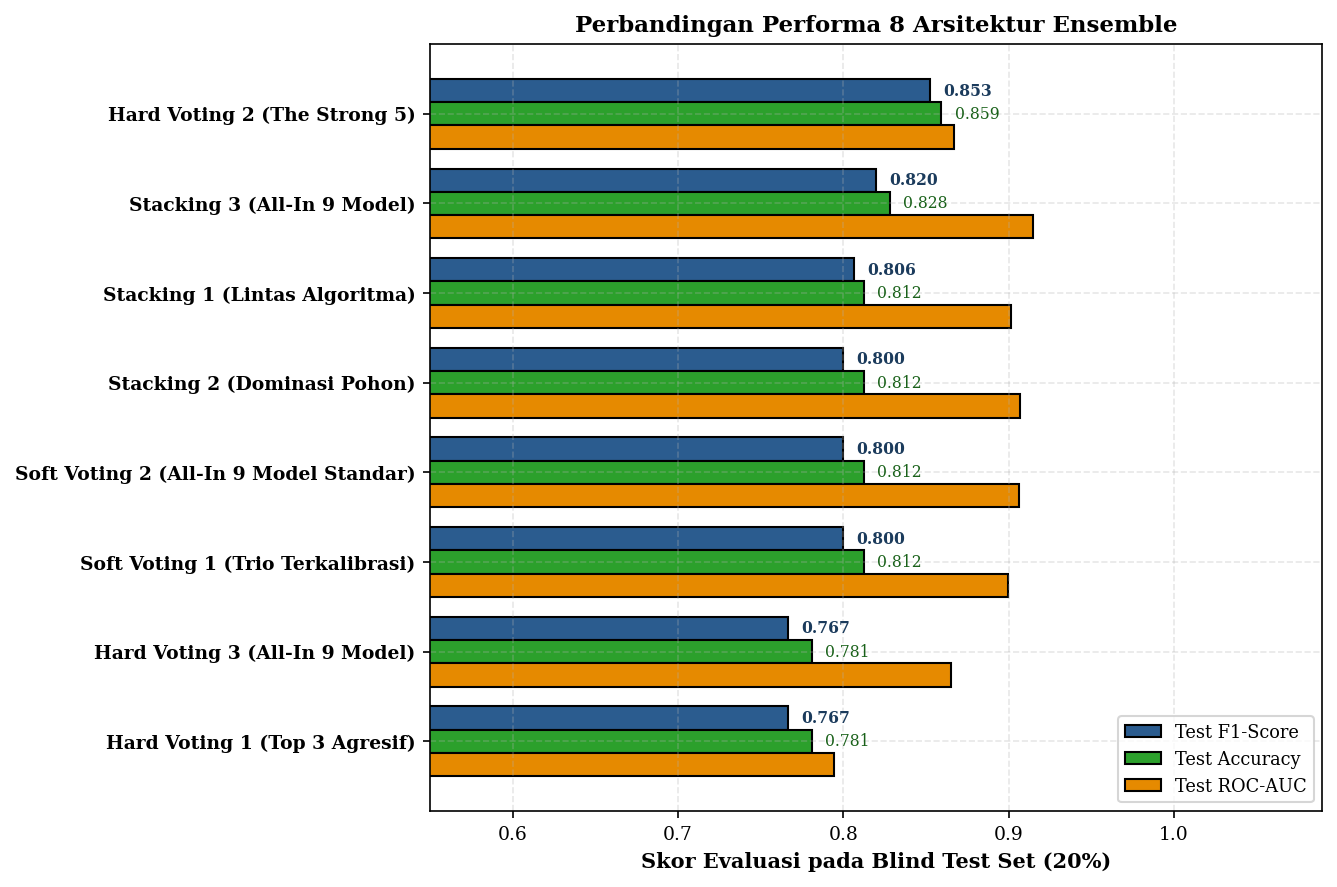

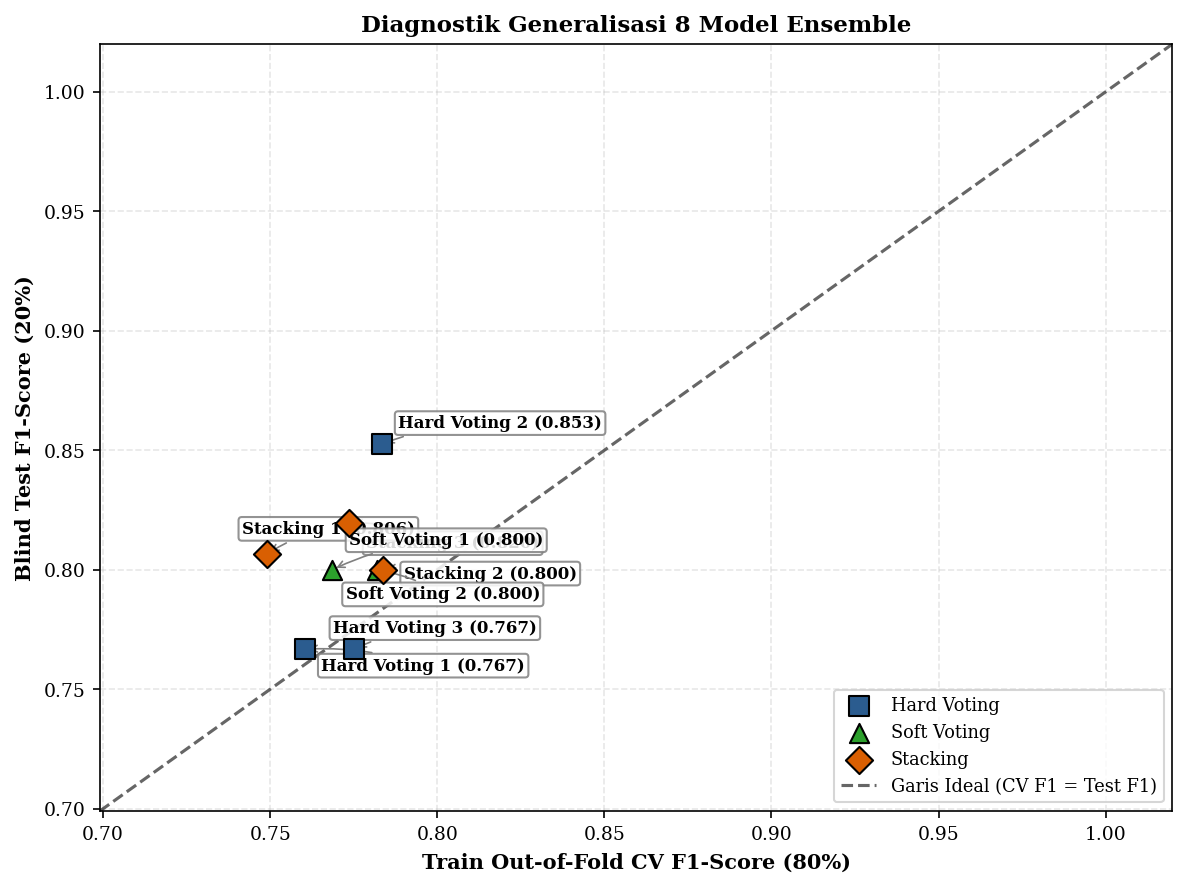

In [23]:
# ==============================================================================
# 7B. VISUALISASI KOMPARASI HASIL EVALUASI 8 MODEL ENSEMBLE (TERPISAH | IEEE)
# ==============================================================================

# Gambar (a): Peringkat Test F1-Score vs Test Accuracy vs Test ROC-AUC untuk 8 Ensemble
fig, ax0 = plt.subplots(figsize=(8.8, 5.8), constrained_layout=True)
df_plot = results_df.iloc[::-1].copy()
y_pos = np.arange(len(df_plot))
height = 0.26

bars_f1 = ax0.barh(y_pos + height, df_plot['Test F1-Score'], height=height, label='Test F1-Score', color='#2b5c8f', edgecolor='black')
bars_acc = ax0.barh(y_pos, df_plot['Test Accuracy'], height=height, label='Test Accuracy', color='#2ca02c', edgecolor='black')
bars_auc = ax0.barh(y_pos - height, df_plot['Test ROC-AUC'], height=height, label='Test ROC-AUC', color='#e68a00', edgecolor='black')

for bar in bars_f1:
    w = bar.get_width()
    ax0.text(w + 0.008, bar.get_y() + bar.get_height()/2., f"{w:.3f}", va='center', ha='left', fontsize=7.5, fontweight='bold', color='#1b3b5c')

for bar in bars_acc:
    w = bar.get_width()
    ax0.text(w + 0.008, bar.get_y() + bar.get_height()/2., f"{w:.3f}", va='center', ha='left', fontsize=7.5, color='#196119')

ax0.set_yticks(y_pos)
ax0.set_yticklabels(df_plot['Model Ensemble'], fontsize=9, fontweight='bold')
ax0.set_xlim(0.55, 1.09)
ax0.set_xlabel("Skor Evaluasi pada Blind Test Set (20%)")
ax0.set_title("Perbandingan Performa 8 Arsitektur Ensemble")
ax0.legend(loc='lower right')
plt.savefig("Fig7a_Perbandingan_Performa_Ensemble_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Gambar (b): Analisis Generalisasi 8 Ensemble (Train CV F1 vs Blind Test F1-Score)
fig, ax1 = plt.subplots(figsize=(7.8, 5.8), constrained_layout=True)
type_colors = {'Hard Voting': '#2b5c8f', 'Soft Voting': '#2ca02c', 'Stacking': '#d95f02'}
type_markers = {'Hard Voting': 's', 'Soft Voting': '^', 'Stacking': 'D'}

for ens_t in ['Hard Voting', 'Soft Voting', 'Stacking']:
    sub = results_df[results_df['Tipe Ensemble'] == ens_t]
    ax1.scatter(
        sub['CV F1 (Train)'], sub['Test F1-Score'],
        color=type_colors[ens_t], marker=type_markers[ens_t],
        s=85, edgecolor='black', label=ens_t, zorder=4
    )

offsets = [(8, 8), (8, -12), (-12, 10), (10, -4), (-15, -14), (8, 12), (-10, 8), (8, -10)]
for i_idx, r in results_df.iterrows():
    short_lbl = r['Model Ensemble'].split(' (')[0]
    dx, dy = offsets[i_idx % len(offsets)]
    ax1.annotate(
        f"{short_lbl} ({r['Test F1-Score']:.3f})",
        (r['CV F1 (Train)'], r['Test F1-Score']),
        xytext=(dx, dy), textcoords='offset points',
        fontsize=8, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='gray', alpha=0.85),
        arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.1', color='gray', lw=0.8)
    )

min_lim = min(results_df['CV F1 (Train)'].min(), results_df['Test F1-Score'].min()) - 0.05
lims = [max(0.5, min_lim), 1.02]
ax1.plot(lims, lims, 'k--', alpha=0.6, label='Garis Ideal (CV F1 = Test F1)')
ax1.set_xlim(lims)
ax1.set_ylim(lims)
ax1.set_xlabel("Train Out-of-Fold CV F1-Score (80%)")
ax1.set_ylabel("Blind Test F1-Score (20%)")
ax1.set_title("Diagnostik Generalisasi 8 Model Ensemble")
ax1.legend(loc='lower right')
plt.savefig("Fig7b_Diagnostik_Generalisasi_Ensemble_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()


=== RINGKASAN DIAGNOSTIK MODEL ENSEMBLE TERBAIK (SKEMA 80:20) ===
Model Ensemble Terbaik    : Hard Voting 2 (The Strong 5)
Tipe Arsitektur           : Hard Voting
  -> Train CV F1-Score    : 0.7833
  -> Blind Test Accuracy  : 0.8594
  -> Blind Test Precision : 0.8966
  -> Blind Test Recall    : 0.8125
  -> Blind Test F1-Score  : 0.8525
  -> Blind Test ROC-AUC   : 0.8667
  -> Blind Test Brier Loss: 0.1481



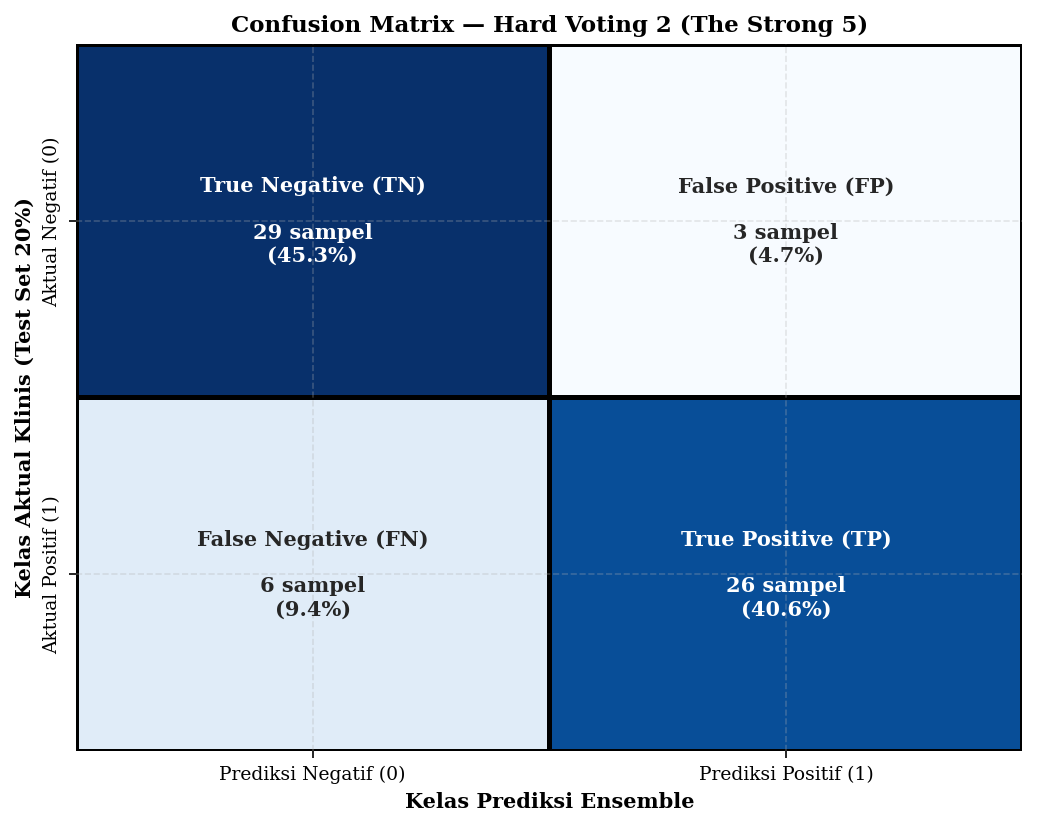

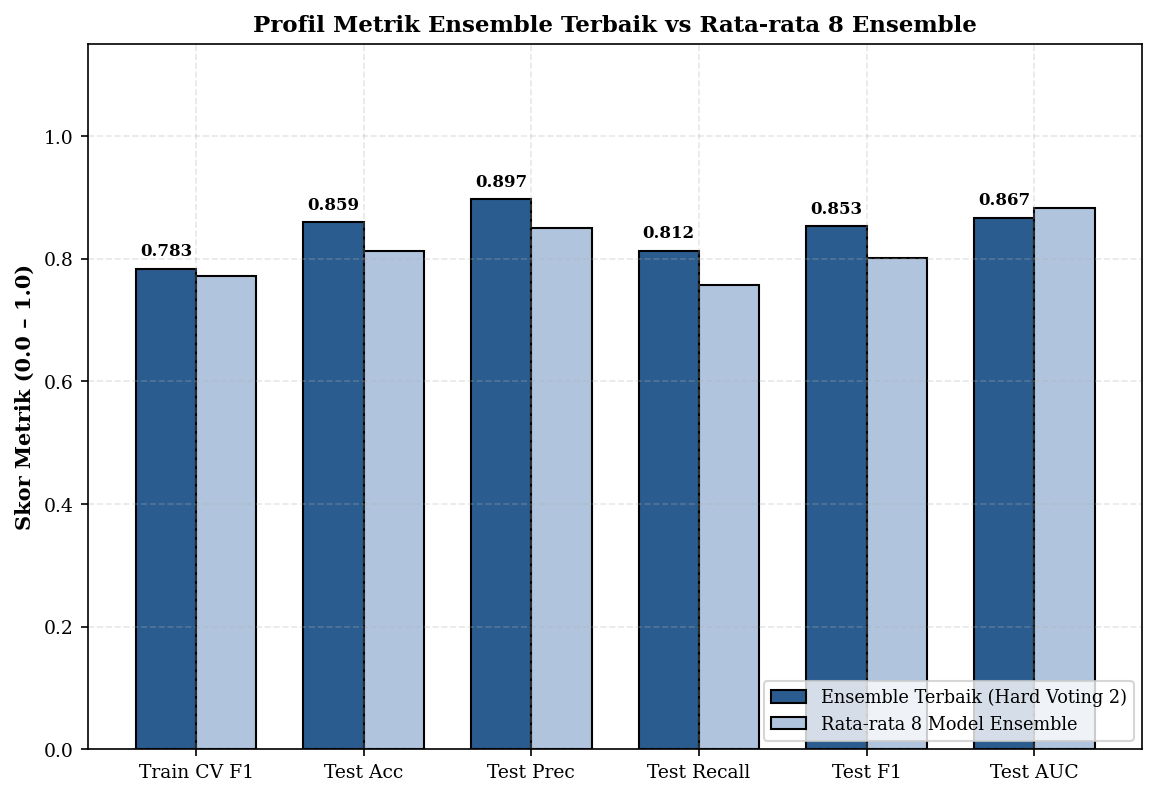

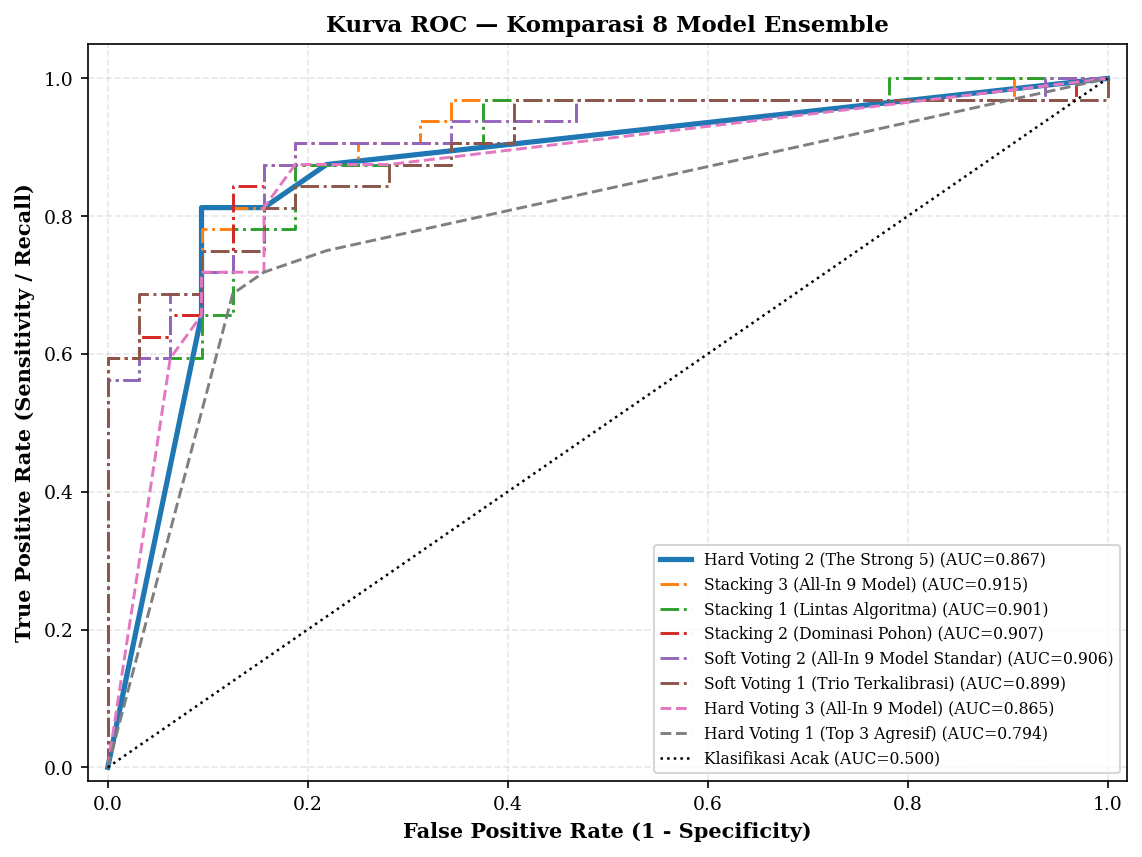

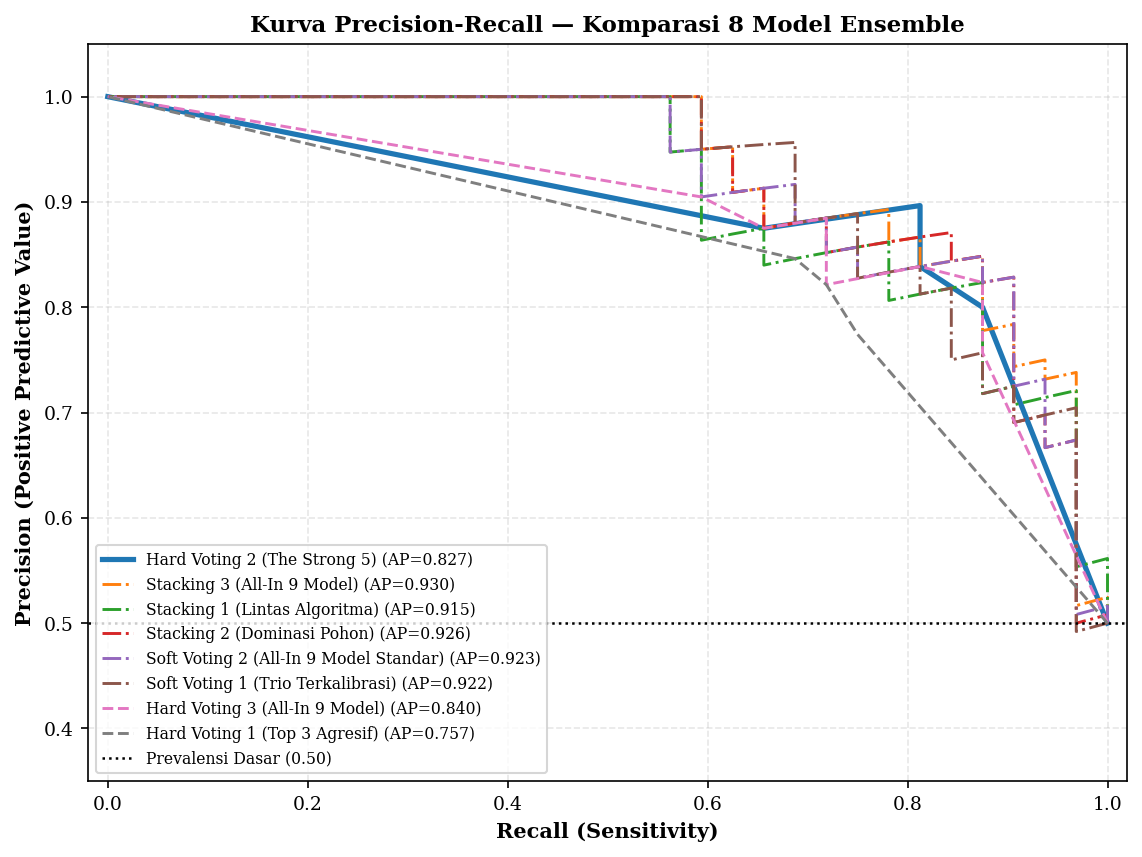

In [24]:
# ==============================================================================
# 7C. VISUALISASI DIAGNOSTIK MODEL ENSEMBLE TERBAIK (4-PANEL IEEE DASHBOARD)
# ==============================================================================
best_row = results_df.iloc[0]
best_ens_name = best_row['Model Ensemble']

print("=== RINGKASAN DIAGNOSTIK MODEL ENSEMBLE TERBAIK (SKEMA 80:20) ===")
print(f"Model Ensemble Terbaik    : {best_ens_name}")
print(f"Tipe Arsitektur           : {best_row['Tipe Ensemble']}")
print(f"  -> Train CV F1-Score    : {best_row['CV F1 (Train)']:.4f}")
print(f"  -> Blind Test Accuracy  : {best_row['Test Accuracy']:.4f}")
print(f"  -> Blind Test Precision : {best_row['Test Precision']:.4f}")
print(f"  -> Blind Test Recall    : {best_row['Test Recall']:.4f}")
print(f"  -> Blind Test F1-Score  : {best_row['Test F1-Score']:.4f}")
print(f"  -> Blind Test ROC-AUC   : {best_row['Test ROC-AUC']:.4f}")
print(f"  -> Blind Test Brier Loss: {best_row['Test Brier Loss']:.4f}\n")

# Gambar (a): Confusion Matrix Model Ensemble Terbaik
fig, ax_cm = plt.subplots(figsize=(6.8, 5.4), constrained_layout=True)
y_pred_best = test_preds_dict[best_ens_name]
cm = confusion_matrix(y_test, y_pred_best)
cm_pct = cm / cm.sum() * 100
annot_cm = np.empty_like(cm, dtype=object)
labels_quad = [['True Negative (TN)', 'False Positive (FP)'], ['False Negative (FN)', 'True Positive (TP)']]
for i in range(2):
    for j in range(2):
        annot_cm[i, j] = f"{labels_quad[i][j]}\n\n{cm[i, j]} sampel\n({cm_pct[i, j]:.1f}%)"

sns.heatmap(
    cm, annot=annot_cm, fmt='', cmap='Blues', cbar=False, ax=ax_cm,
    xticklabels=['Prediksi Negatif (0)', 'Prediksi Positif (1)'],
    yticklabels=['Aktual Negatif (0)', 'Aktual Positif (1)'],
    linewidths=1.5, linecolor='black', annot_kws={'size': 10, 'weight': 'bold'}
)
ax_cm.set_title(f"Confusion Matrix — {best_ens_name}")
ax_cm.set_xlabel("Kelas Prediksi Ensemble")
ax_cm.set_ylabel("Kelas Aktual Klinis (Test Set 20%)")
plt.savefig("Fig8a_Confusion_Matrix_Best_Ensemble_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Gambar (b): Profil 6 Metrik Model Ensemble Terbaik vs Rata-Rata 8 Ensemble
fig, ax_bar = plt.subplots(figsize=(7.6, 5.2), constrained_layout=True)
metrics_cols = ['CV F1 (Train)', 'Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1-Score', 'Test ROC-AUC']
metrics_labels = ['Train CV F1', 'Test Acc', 'Test Prec', 'Test Recall', 'Test F1', 'Test AUC']
best_vals = [best_row[c] for c in metrics_cols]
mean_vals = [results_df[c].mean() for c in metrics_cols]

x_idx = np.arange(len(metrics_labels))
bw = 0.36
b1 = ax_bar.bar(x_idx - bw/2, best_vals, width=bw, label=f"Ensemble Terbaik ({best_ens_name.split(' (')[0]})", color='#2b5c8f', edgecolor='black')
b2 = ax_bar.bar(x_idx + bw/2, mean_vals, width=bw, label='Rata-rata 8 Model Ensemble', color='#b0c4de', edgecolor='black')

for bar in b1:
    h = bar.get_height()
    ax_bar.text(bar.get_x() + bar.get_width()/2., h + 0.015, f"{h:.3f}", ha='center', va='bottom', fontsize=8, fontweight='bold')

ax_bar.set_xticks(x_idx)
ax_bar.set_xticklabels(metrics_labels)
ax_bar.set_ylim(0, 1.15)
ax_bar.set_ylabel("Skor Metrik (0.0 – 1.0)")
ax_bar.set_title("Profil Metrik Ensemble Terbaik vs Rata-rata 8 Ensemble")
ax_bar.legend(loc='lower right')
plt.savefig("Fig8b_Profil_Metrik_Best_vs_Mean_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Gambar (c): Kurva ROC Seluruh 8 Model Ensemble
fig, ax_roc = plt.subplots(figsize=(7.5, 5.6), constrained_layout=True)
palette_8 = sns.color_palette("tab10", len(results_df))

for idx_m, r in results_df.iterrows():
    m_name = r['Model Ensemble']
    y_p = test_probas_dict[m_name]
    fpr, tpr, _ = roc_curve(y_test, y_p)
    auc_val = roc_auc_score(y_test, y_p)
    lw = 2.5 if idx_m == 0 else 1.4
    ls = '-' if idx_m == 0 else '--' if 'Hard' in m_name else '-.'
    ax_roc.plot(fpr, tpr, color=palette_8[idx_m], lw=lw, ls=ls, label=f"{m_name} (AUC={auc_val:.3f})")

ax_roc.plot([0, 1], [0, 1], 'k:', lw=1.2, label='Klasifikasi Acak (AUC=0.500)')
ax_roc.set_xlim(-0.02, 1.02)
ax_roc.set_ylim(-0.02, 1.05)
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Sensitivity / Recall)")
ax_roc.set_title("Kurva ROC — Komparasi 8 Model Ensemble")
ax_roc.legend(loc='lower right', fontsize=7.5)
plt.savefig("Fig8c_Kurva_ROC_8_Ensemble_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Gambar (d): Kurva Precision-Recall Seluruh 8 Model Ensemble
fig, ax_pr = plt.subplots(figsize=(7.5, 5.6), constrained_layout=True)
baseline_pr = y_test.mean()
for idx_m, r in results_df.iterrows():
    m_name = r['Model Ensemble']
    y_p = test_probas_dict[m_name]
    prec_c, rec_c, _ = precision_recall_curve(y_test, y_p)
    ap_val = average_precision_score(y_test, y_p)
    lw = 2.5 if idx_m == 0 else 1.4
    ls = '-' if idx_m == 0 else '--' if 'Hard' in m_name else '-.'
    ax_pr.plot(rec_c, prec_c, color=palette_8[idx_m], lw=lw, ls=ls, label=f"{m_name} (AP={ap_val:.3f})")

ax_pr.axhline(baseline_pr, color='black', linestyle=':', lw=1.2, label=f"Prevalensi Dasar ({baseline_pr:.2f})")
ax_pr.set_xlim(-0.02, 1.02)
ax_pr.set_ylim(max(0.0, baseline_pr - 0.15), 1.05)
ax_pr.set_xlabel("Recall (Sensitivity)")
ax_pr.set_ylabel("Precision (Positive Predictive Value)")
ax_pr.set_title("Kurva Precision-Recall — Komparasi 8 Model Ensemble")
ax_pr.legend(loc='lower left', fontsize=7.5)
plt.savefig("Fig8d_Kurva_PR_8_Ensemble_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()


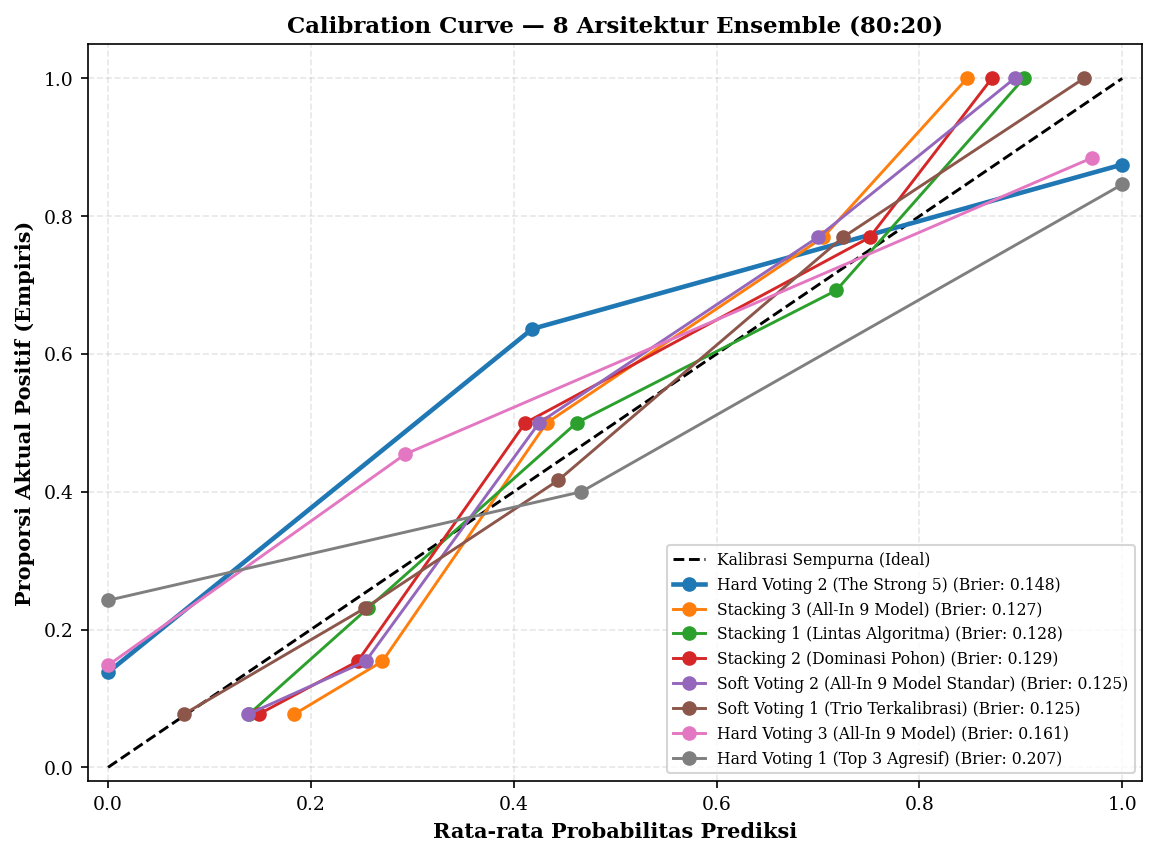

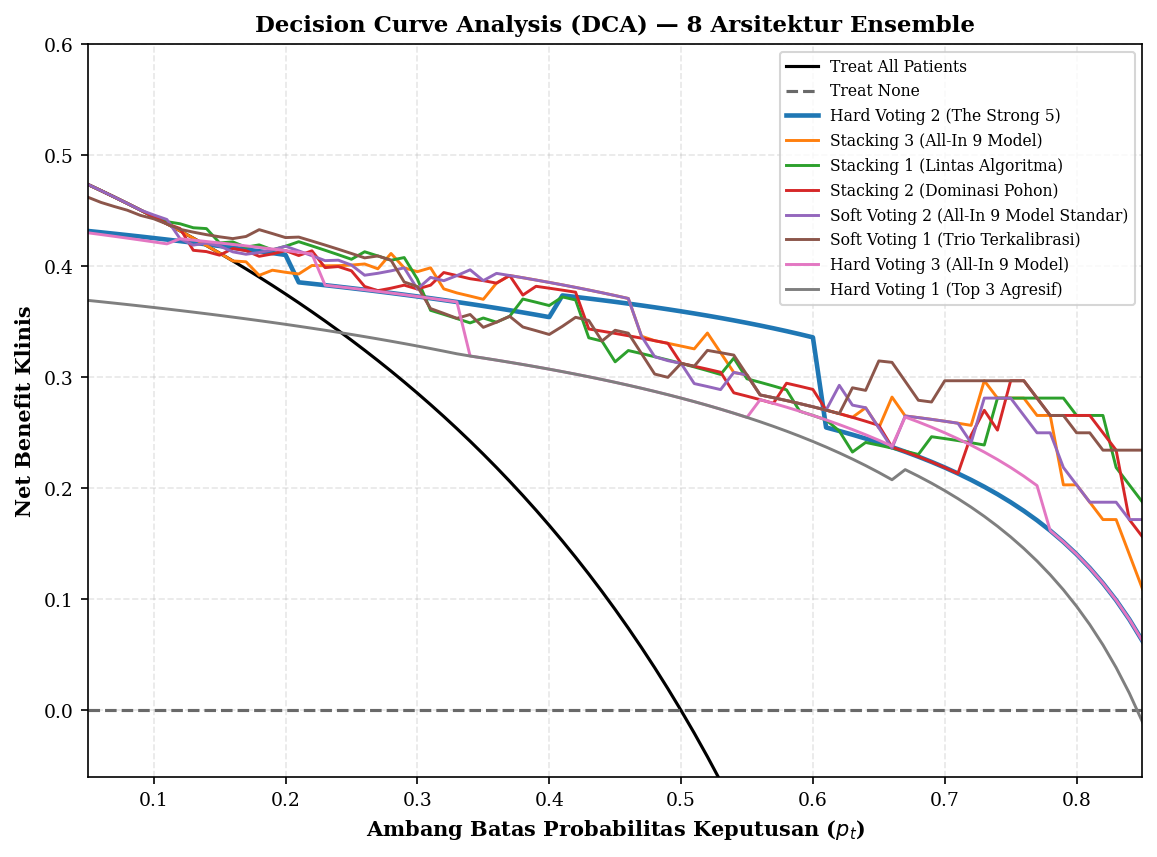

In [25]:
# ==============================================================================
# 7D. KURVA KALIBRASI RELIABILITAS & DECISION CURVE ANALYSIS (TERPISAH | IEEE)
# ==============================================================================
y_test_arr = y_test.values
palette_ens = sns.color_palette("tab10", len(results_df))

# Gambar (a): Calibration Curve (8 Model Ensemble)
fig, ax_cal = plt.subplots(figsize=(7.6, 5.6), constrained_layout=True)
ax_cal.plot([0, 1], [0, 1], 'k--', lw=1.4, label='Kalibrasi Sempurna (Ideal)')
for idx_m, r in results_df.iterrows():
    m_name = r['Model Ensemble']
    y_p = test_probas_dict[m_name]
    brier = brier_score_loss(y_test_arr, y_p)
    prob_true, prob_pred = calibration_curve(y_test_arr, y_p, n_bins=5, strategy='quantile')
    lw = 2.2 if idx_m == 0 else 1.4
    ax_cal.plot(prob_pred, prob_true, marker='o', color=palette_ens[idx_m], lw=lw, label=f"{m_name} (Brier: {brier:.3f})")

ax_cal.set_title("Calibration Curve — 8 Arsitektur Ensemble (80:20)")
ax_cal.set_xlabel("Rata-rata Probabilitas Prediksi")
ax_cal.set_ylabel("Proporsi Aktual Positif (Empiris)")
ax_cal.set_xlim(-0.02, 1.02)
ax_cal.set_ylim(-0.02, 1.05)
ax_cal.legend(loc='lower right', fontsize=7.5)
plt.savefig("Fig9a_Calibration_Curve_8_Ensemble_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()

# Gambar (b): Decision Curve Analysis / DCA (8 Model Ensemble)
fig, ax_dca = plt.subplots(figsize=(7.6, 5.6), constrained_layout=True)
thresholds = np.linspace(0.05, 0.85, 81)
N = len(y_test_arr)
prevalence = np.mean(y_test_arr)

net_benefit_all = prevalence - (1 - prevalence) * (thresholds / (1 - thresholds))
ax_dca.plot(thresholds, net_benefit_all, 'k-', lw=1.5, label='Treat All Patients')
ax_dca.axhline(0, color='dimgray', linestyle='--', lw=1.5, label='Treat None')

for idx_m, r in results_df.iterrows():
    m_name = r['Model Ensemble']
    y_p = test_probas_dict[m_name]
    net_benefits = []
    for pt in thresholds:
        preds_pt = (y_p >= pt).astype(int)
        tp = np.sum((preds_pt == 1) & (y_test_arr == 1))
        fp = np.sum((preds_pt == 1) & (y_test_arr == 0))
        nb = (tp / N) - (fp / N) * (pt / (1 - pt))
        net_benefits.append(nb)
    lw = 2.2 if idx_m == 0 else 1.4
    ax_dca.plot(thresholds, net_benefits, color=palette_ens[idx_m], lw=lw, label=m_name)

ax_dca.set_xlim(0.05, 0.85)
ax_dca.set_ylim(-0.06, max(prevalence + 0.08, 0.60))
ax_dca.set_title("Decision Curve Analysis (DCA) — 8 Arsitektur Ensemble")
ax_dca.set_xlabel("Ambang Batas Probabilitas Keputusan ($p_t$)")
ax_dca.set_ylabel("Net Benefit Klinis")
ax_dca.legend(loc='upper right', fontsize=7.5)
plt.savefig("Fig9b_Decision_Curve_Analysis_8_Ensemble_IEEE.png", dpi=300, bbox_inches='tight')
plt.show()
